# Integrative Assay Summary

In [1]:
import sys
import polars as pl
import pandas as pd
import numpy as np
# Create heatmap with custom colors
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedFormatter, FixedLocator
import matplotlib as mpl
from matplotlib.patches import Patch
import matplotlib.font_manager as fm
from scipy.stats import fisher_exact, mannwhitneyu
from matplotlib.gridspec import GridSpec
from statannotations.Annotator import Annotator

# Force TrueType font embedding (Type 42)
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

font_path = "../../1_allele_collection/4_manuscript_figures/ARIAL.TTF"
fm.fontManager.addfont(font_path)

font_prop = fm.FontProperties(fname=font_path)
# Set font family to one of the accepted fonts
plt.rcParams.update({
    "font.family": font_prop.get_name(),
    "font.sans-serif": ["ARIAL"],
    "font.size": 12,
    "axes.labelsize": 12,
    "axes.titlesize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
})

# Verify settings
# print(f"pdf.fonttype: {mpl.rcParams['pdf.fonttype']}")
# print(f"ps.fonttype: {mpl.rcParams['ps.fonttype']}")
# print(f"font.family: {mpl.rcParams['font.family']}")

sys.path.append("../../1_allele_collection/2_analysis")
from plot_utils import *
sys.path.append("../../2_individual_assay_results")
from analyses_plot_utils import *

## 1. Loading data

### 1.1 Merge allele collection with DUAL-IPA, Imaging and PPI assays

In [2]:
dualipa_outputs = "../../2_individual_assay_results/dual_ipa/3_outputs"
imaging_outputs = "../../2_individual_assay_results/imaging/3_outputs"
ppi_outputs = "../../2_individual_assay_results/ppi/3_outputs/sqY2H"

allele_col_df = pl.read_csv(f"../../1_allele_collection/3_outputs/VarChAMP_Allele_Collection_1Perc_ClinVar_dbNSFP_pLDDT_RSA_G2P_OMIM_MOI_SpliceAI_AM_Analysis.tsv", 
                            separator="\t", infer_schema_length=100000).with_columns(
                                pl.col("clinvar_clnsig_clean").replace("6_No_ClinVar", "5_Others")
                            )
                            
dualipa = pl.read_csv(f"{dualipa_outputs}/annotated_perturbation_scores.csv", infer_schema_length=100000).with_columns(
    pl.when(pl.col("dualipa_abun_change")=="Y")
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("dualipa_hit")
)
print("DUAL-IPA:", dualipa.shape[0], dualipa.unique(subset="gene_variant").shape[0])

imaging = pl.read_csv(
    f"{imaging_outputs}/0_imaging_phenotype_summary_clinvar.tsv", separator="\t", infer_schema_length=100000
).rename(
    {
        "U2OS_cc_t_stat": "img_U2OS_cc_t_stat",
        "U2OS_cc_t_pval": "img_U2OS_cc_t_pval",
        "U2OS_cc_t_pval_fdr_bh_adj": "img_U2OS_cc_t_adj_pval",
        "U2OS_prot_abun_t_stat": "img_U2OS_prot_abun_t_stat",
        "U2OS_prot_abun_t_pval": "img_U2OS_prot_abun_t_pval",
        "U2OS_prot_abun_t_pval_fdr_bh_adj": "img_U2OS_prot_abun_t_adj_pval",
        "Metadata_Bio_Batch": "img_Metadata_Bio_Batch"
    }
).with_columns(
    pl.when(pl.col("img_pheno_hit"))
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("imaging_hit")
)
print("Imaging:", imaging.shape[0], imaging.unique(subset="gene_variant").shape[0])

ppi = pl.read_csv(f"{ppi_outputs}/orf_distances_final_with_edgotype.csv", infer_schema_length=100000)
ppi = ppi.rename(
    {
        "db_orf_id": "orf_id", "db_mut_id": "mut_id", 
        "norm_dist_rms": "ppi_norm_dist_rms",
        "num_edges": "ppi_num_edges",
    }
)

print("PPI:", ppi.shape[0], ppi.unique(subset="gene_variant").shape[0])

## Select key cols per each assay
dualipa_key_cols = ['dualipa_abun_score', 'dualipa_abun_change', 'dualipa_abun_chg_dir', 'dualipa_hit'] #[c for c in dualipa.columns if c not in allele_col_df.columns]
ppi_key_cols = [c for c in ppi.columns if c not in allele_col_df.columns] #[c for c in ppi.columns if c not in allele_col_df.columns]
img_key_cols = [c for c in imaging.columns if c not in allele_col_df.columns and c.startswith("img_")] + ['imaging_hit'] # [c for c in imaging.columns if c not in allele_col_df.columns]

DUAL-IPA: 791 791
Imaging: 794 794
PPI: 502 502


In [3]:
n_var = len(imaging)

n_wt = imaging.to_pandas().symbol.nunique()

((n_var + n_wt) * 4) + 12595 + 2105

18340

In [4]:
al_dual_df = allele_col_df.with_columns(
    pl.col("mut_id").cast(pl.Int64).alias("mut_id")
).join(
    dualipa.select(["orf_id", "mut_id"]+dualipa_key_cols),
    left_on=["orf_id", "mut_id"],
    right_on=["orf_id", "mut_id"],
    how="left"
)

al_dual_ppi = al_dual_df.join(
    ppi.select(["orf_id", "mut_id"]+ppi_key_cols),
    left_on=["orf_id", "mut_id"],
    right_on=["orf_id", "mut_id"],
    how="left",
    suffix="_ppi"
)

al_dual_img_ppi = al_dual_ppi.join(
    imaging.select(["gene_variant"]+img_key_cols),
    on="gene_variant",
    how="left",
    suffix="_img"
)

print(al_dual_img_ppi.drop_nulls("dualipa_abun_score").shape)
print(al_dual_img_ppi.drop_nulls("img_pheno_score").shape)
print(al_dual_img_ppi.drop_nulls("ppi_norm_dist_rms").shape)

(839, 1036)
(980, 1036)
(543, 1036)


### 1.2 De-duplicate variants

In [5]:
display(al_dual_img_ppi.filter(
    pl.col("spdi").is_duplicated(),
    pl.col("gene_variant")=="AGXT_Gly41Arg"
).select(
    "gene_variant","spdi","collection","dualipa_abun_score","img_pheno_score","ppi_norm_dist_rms"
))

### VERY VERY VERY IMPORTANT STEP!!!
### Since per the same genetic variant, we may have multiple copies of it in different allele collections,
### the SAME variant may be profiled by an assay IN DIFFERENT ALLELE COLLECTION (shown below)
### And we need to merge them all together to the same VARIANT level
al_dual_img_ppi = al_dual_img_ppi.with_columns([
    pl.col(c).fill_null(pl.col(c).drop_nulls().first()).over("gene_variant")
    for c in dualipa_key_cols+ppi_key_cols+img_key_cols
])

gene_variant,spdi,collection,dualipa_abun_score,img_pheno_score,ppi_norm_dist_rms
str,str,str,f64,f64,f64
"""AGXT_Gly41Arg""","""NC_000002.12:240868985:G:A""","""CEGS2""",null,0.811078,0.43388
"""AGXT_Gly41Arg""","""NC_000002.12:240868985:G:A""","""Edgotyping3""",null,0.811078,0.43388
"""AGXT_Gly41Arg""","""NC_000002.12:240868985:G:A""","""CEGS2""",-1.869887,0.811078,null
"""AGXT_Gly41Arg""","""NC_000002.12:240868985:G:A""","""Edgotyping3""",-1.869887,0.811078,null


In [6]:
al_dual_img_ppi_assayed = al_dual_img_ppi.filter(
    pl.col("dualipa_abun_score").is_not_null()
    | pl.col("img_pheno_score").is_not_null()
    | pl.col("ppi_norm_dist_rms").is_not_null()
)

al_dual_img_ppi_assayed_dedup = al_dual_img_ppi_assayed.rename(
    {
        "dualipa_abun_score": "dualipa_score",
        "img_pheno_score": "imaging_score",
        "ppi_norm_dist_rms": "ppi_score"
    }
).with_columns(
    pl.col("gene_variant").str.split("_").list.get(0).alias("symbol"),
    pl.sum_horizontal(
        pl.col("dualipa_score").is_not_null(),
        pl.col("imaging_score").is_not_null(),
        pl.col("ppi_score").is_not_null(),
    ).alias("_non_null_count"),
    pl.col("clinvar_clnsig_clean").fill_null("Others"),
    pl.col("clinvar_clnsig_clean_pp_strict").fill_null("Others")
).sort(
    "_non_null_count", descending=True
).unique(
    subset=["gene_variant"], keep="first"
).drop(
    "_non_null_count"
)

In [7]:
print("Profiled in any assay:", al_dual_img_ppi_assayed_dedup.shape[0])
print("Profiled in DUALIPA assay:", al_dual_img_ppi_assayed_dedup.filter(
    pl.col("dualipa_score").is_not_null()
).shape[0])
print("Profiled in Imaging assay:", al_dual_img_ppi_assayed_dedup.filter(
    pl.col("imaging_score").is_not_null()
).shape[0])
print("Profiled in PPI assay:", al_dual_img_ppi_assayed_dedup.filter(
    pl.col("ppi_score").is_not_null()
).shape[0])

Profiled in any assay: 1407
Profiled in DUALIPA assay: 791
Profiled in Imaging assay: 794
Profiled in PPI assay: 502


In [ ]:
# al_dual_img_ppi_assayed_dedup.sort(
#     "gene_variant"
# ).write_csv("../3_outputs/0_all_gene_variants_assayed_summary.tsv", separator="\t")

# al_dual_img_ppi_assayed_dedup.select(
#     "symbol",
#     "gene_variant",
#     "clinvar_clnsig_clean",
#     "clinvar_clnsig_clean_pp_strict",
#     "dualipa_score",
#     "imaging_score",
#     "ppi_score",
#     "dualipa_hit",
#     "imaging_hit",
#     "ppi_hit"
# ).sort(
#     "gene_variant"
# ).write_csv("../3_outputs/0_all_gene_variants_assayed_summary_key_cols.tsv", separator="\t")

In [ ]:
# Generate final table for supp mat of PP

# Generate HGVS_c
# First approach doesn't work, some missing values in ChromosomeAccession/PositionVCF/ReferenceAlleleVCF/AlternateAlleleVCF
# al_dual_img_ppi_assayed_dedup = al_dual_img_ppi_assayed_dedup.with_columns(
#                     HGVS_c=pl.col("ChromosomeAccession") + ":" +
#                     "g" + "." +
#                     pl.col("PositionVCF").cast(pl.Int64).cast(pl.String) +
#                     pl.col("ReferenceAlleleVCF") + ">" +
#                     pl.col("AlternateAlleleVCF")
#                 )

# DUAL-IPA scores:   IGVFDS0761PJSK

# semi_qY2H_ppi_analysis: IGVFDS9160DECF

# semi_qY2H_orf_distance_analysis: IGVFDS9876GIEQ

# Variant painting: IGVFDS4288KLWA

DACC_acc_ids = {'dualipa': 'IGVFDS0761PJSK',
                'ppi': 'IGVFDS9160DECF',
                'ppi_dist': 'IGVFDS9876GIEQ',
                'imaging': 'IGVFDS4288KLWA'}

al_dual_img_ppi_assayed_dedup = al_dual_img_ppi_assayed_dedup.with_columns(
                    HGVS_c=pl.col("spdi").cast(pl.String).str.split(':').list.get(0) + ":" +
                    "g" + "." +
                    pl.col("nuc_loc").cast(pl.Int64).cast(pl.String) +
                    pl.col("ref_allele") + ">" +
                    pl.col("alt_allele")
                )

# for var in al_dual_img_ppi_assayed_dedup["HGVS_c"]:
    # print(var)


# map assay score columns to their DACC accession IDs where we have data
al_dual_img_ppi_assayed_dedup = al_dual_img_ppi_assayed_dedup.with_columns(
    pl.when(pl.col("dualipa_score").is_not_null())
    .then(pl.lit(DACC_acc_ids['dualipa']))
    .otherwise(pl.lit(None))
    .alias("dualipa_DACC_accession_id"),
    pl.when(pl.col("imaging_score").is_not_null())
    .then(pl.lit(DACC_acc_ids['imaging']))
    .otherwise(pl.lit(None))
    .alias("imaging_DACC_accession_id"),
    pl.when(pl.col("ppi_score").is_not_null())
    .then(pl.lit(DACC_acc_ids['ppi_dist']))
    .otherwise(pl.lit(None))
    .alias("ppi_DACC_accession_id"),
)

    
cols_to_keep = [
    "symbol",
    'gene_variant',
    'ensembl_gene_id',
    'aa_change',
    "HGVS_c",
    "clinvar_clnsig_clean",
    "clinvar_clnsig_clean_pp_strict",
    "dualipa_score",
    "imaging_score",
    "ppi_score",
    "dualipa_hit",
    "imaging_hit",
    "ppi_hit",
    "dualipa_DACC_accession_id",
    "imaging_DACC_accession_id",
    "ppi_DACC_accession_id"
]

al_dual_img_ppi_assayed_dedup.select(
    cols_to_keep
).sort(
    "gene_variant"
).drop(
    "gene_variant"
).write_csv("../3_outputs/VarChAMP_data_supp_mat_PP.tsv", separator="\t")

al_dual_img_ppi_assayed_dedup.select(
    cols_to_keep
).sort(
    "gene_variant"
).drop(
    "gene_variant"
)

symbol,ensembl_gene_id,aa_change,HGVS_c,clinvar_clnsig_clean,clinvar_clnsig_clean_pp_strict,dualipa_score,imaging_score,ppi_score,dualipa_hit,imaging_hit,ppi_hit,dualipa_DACC_accession_id,imaging_DACC_accession_id,ppi_DACC_accession_id
str,str,str,str,str,str,f64,f64,f64,bool,bool,bool,str,str,str
"""ABCD1""","""ENSG00000101986""","""Arg389Gly""","""NC_000023.11:g.153736195C>G""","""Pathogenic""","""Pathogenic""",null,0.693378,null,null,false,null,null,"""IGVFDS4288KLWA""",null
"""ABCD1""","""ENSG00000101986""","""Arg518Gln""","""NC_000023.11:g.153740156G>A""","""Pathogenic""","""Pathogenic""",null,0.784993,null,null,false,null,null,"""IGVFDS4288KLWA""",null
"""ACSF3""","""ENSG00000176715""","""Ala17Pro""","""NC_000016.10:g.89100730G>C""","""Benign""","""Benign""",-1.25683,null,null,false,null,null,"""IGVFDS0761PJSK""",null,null
"""ACSF3""","""ENSG00000176715""","""Ala197Thr""","""NC_000016.10:g.89101270G>A""","""Conflicting""","""Conflicting""",-0.814021,null,null,false,null,null,"""IGVFDS0761PJSK""",null,null
"""ACSF3""","""ENSG00000176715""","""Arg10Trp""","""NC_000016.10:g.89100709C>T""","""VUS""","""VUS""",null,null,0.673632,null,null,true,null,null,"""IGVFDS9876GIEQ"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""ZC4H2""","""ENSG00000126970""","""Pro201Ser""","""NC_000023.11:g.64917857G>A""","""Pathogenic""","""Likely pathogenic""",null,0.802143,null,null,false,null,null,"""IGVFDS4288KLWA""",null
"""ZC4H2""","""ENSG00000126970""","""Val63Leu""","""NC_000023.11:g.64921855C>G""","""Pathogenic""","""Pathogenic""",null,0.92116,null,null,false,null,null,"""IGVFDS4288KLWA""",null
"""ZMYND10""","""ENSG00000004838""","""Arg243Cys""","""NC_000003.12:g.50342543G>A""","""Benign""","""Likely benign""",null,0.904041,null,null,false,null,null,"""IGVFDS4288KLWA""",null


In [ ]:
ppi_threshold = 0.542
# abundance
path_thres, benign_thres_bottom, benign_thres_top, path_thres_2 = -2.522, -0.566, 0.932, 1.994


In [ ]:
# Overall DUAL-IPA hit rate
dualipa_total = al_dual_img_ppi_assayed_dedup.filter(pl.col("dualipa_hit").is_not_null()).shape[0]
dualipa_hits = al_dual_img_ppi_assayed_dedup.filter(pl.col("dualipa_hit") == True).shape[0]
print(f"DUAL-IPA hit rate (all): {dualipa_hits}/{dualipa_total} = {dualipa_hits/dualipa_total:.2%}")

# By ClinVar category (Pathogenic/Benign)
for cat in ["Pathogenic", "Benign"]:
    df = al_dual_img_ppi_assayed_dedup.filter(
        pl.col("clinvar_clnsig_clean") == cat,
        pl.col("dualipa_hit").is_not_null()
    )
    total = df.shape[0]
    hits = df.filter(pl.col("dualipa_hit") == True).shape[0]
    print(f"DUAL-IPA hit rate ({cat}): {hits}/{total} = {hits/total:.2%}" if total > 0 else f"No data for {cat}")

DUAL-IPA hit rate (all): 266/791 = 33.63%
DUAL-IPA hit rate (Pathogenic): 147/353 = 41.64%
DUAL-IPA hit rate (Benign): 6/68 = 8.82%


In [ ]:
al_dual_img_ppi_assayed_dedup

symbol,aa_change,gene_variant,spdi,nt_change,chr_num,nuc_loc,ref_allele,alt_allele,Chrom,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,seq,seq_aa,ensembl_protein_id,collection,entry_plate_orig,entry_well_orig,entry_plate_conso,entry_well_conso,entry_seq_pool,db_plate,db_well,n2h_plate,n2h_well,dualip_plate,dualip_well,mislocalization_plate,mislocalization_well,entry_sequenced,entry_sequence_confirmation_class,db_sequenced,db_sequence_confirmation_class,n2h_sequenced,…,g2p_Transit peptide (UniProt),g2p_Transmembrane (UniProt),g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant,am_pathogenicity,dualipa_score,dualipa_abun_change,dualipa_abun_chg_dir,dualipa_hit,ppi_num_edges,ppi_score,ppi_hit,img_U2OS_cc_t_stat,img_U2OS_cc_t_pval,img_U2OS_cc_t_adj_pval,img_U2OS_prot_abun_t_stat,img_U2OS_prot_abun_t_pval,img_U2OS_prot_abun_t_adj_pval,img_Metadata_Bio_Batch,imaging_score,img_misloc_score,img_pheno_hit,img_misloc_hit,img_pheno_hit_strict,imaging_hit,HGVS_c
str,str,str,str,str,i64,i64,str,str,str,str,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,f64,f64,f64,…,str,str,str,str,f64,f64,str,str,str,str,str,str,i64,str,bool,f64,f64,str,str,bool,i64,f64,bool,f64,f64,f64,f64,f64,f64,str,f64,f64,bool,bool,bool,bool,str
"""SFTPC""","""His64Pro""","""SFTPC_His64Pro""","""NC_000008.11:22162721:A:C""","""191A>C""",8,22162722,"""A""","""C""","""8""","""ENSG00000168484""",5723,10351,"""CCSBVarC000890""","""ALE00000890""","""ATGGATGTGGGCAGCAAAGAGGTCCTGATG…","""MDVGSKEVLMESPPDYSAAPRGRFGIPCCP…","""ENSP00000316152.3""","""RC4""","""RC4_Mut_GDEh1012""","""A06""","""GDEhDisVCh_40072""","""D08""","""2""","""RC4_Mut_GDDh1012""","""A06""","""NULL""","""NULL""","""VUSMutpDEST2_05""","""C06""","""NULL""","""NULL""",1.0,1.0,1.0,1.0,0.0,…,null,null,null,null,null,null,"""NaN""","""NaN""",null,null,null,"""Rare genetic respiratory disea…",1,null,false,0.7687,-0.810717,"""Uncertain""","""Decrease""",false,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""NC_000008.11:g.22162722A>C"""
"""AGXT""","""Leu26Pro""","""AGXT_Leu26Pro""","""NC_000002.12:240868941:T:C""","""77T>C""",2,240868942,"""T""","""C""","""2""","""ENSG00000172482""",70497,3788,"""CCSBVarC008162""","""ALE00008148""","""ATGGCCTCTCACAAGCTGCTGGTGACCCCC…","""MASHKLLVTPPKALLKPLSIPNQLLPGPGP…","""ENSP00000302620.3""","""Edgotyping3""","""VUSMutGDEh003""","""H11""","""GDEhDisVCh_40002""","""A02""","""2""","""VUSMutGDDh003""","""H11""","""NULL""","""NULL""","""VUSMutpDEST2_14""","""D01""","""NULL""","""NULL""",1.0,1.0,1.0,1.0,0.0,…,null,null,null,null,98.91,0.0,""">90""","""<10""","""259900""","""autosomal recessive""","""OMIM""","""Rare genetic eye disease; Rare…",3,"""HYPEROXALURIA, PRIMARY, TYPE I""",false,0.8173,-3.385465,"""Y""","""Decrease""",true,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""NC_000002.12:g.240868942T>C"""
"""HBD""","""Asn58Lys""","""HBD_Asn58Lys""","""NC_000011.10:5234131:G:T""","""174C>A""",11,5234132,"""G""","""T""","""11""","""ENSG00000223609""",13796,218146,"""CCSBVarC006560""","""ALE00006559""","""ATGGTGCATCTGACTCCTGAGGAGAAGACT…","""MVHLTPEEKTAVNALWGKVNVDAVGGEALG…","""ENSP00000497529.1""","""CEGS2""","""CegsMutGDEh1047""","""D02""","""GDEhDisVCh_40036""","""D03""","""2""","""CegsMutGDDh1047""","""D02""","""VUSN2Hmut_GDN2h_10""","""C04""","""VUSMutpDEST2_11""","""H05""","""VUSmut_GDEh10""","""C04""",1.0,1.0,1.0,1.0,1.0,…,null,null,null,null,98.57,7.6433125,""">90""","""<10""",null,null,null,"""Rare genetic hematologic disea…",1,null,false,0.987,-6.480958,"""Y""","""Decrease""",true,2,0.711181,true,2.027367,0.098441,0.162088,-0.880748,0.41234,0.465775,"""2024_01_Batch_7-8""",0.623194,0.586093,false,false,false,false,"""NC_000011.10:g.5234132G>T"""
"""HMBS""","""Arg225Gln""","""HMBS_Arg225Gln""",

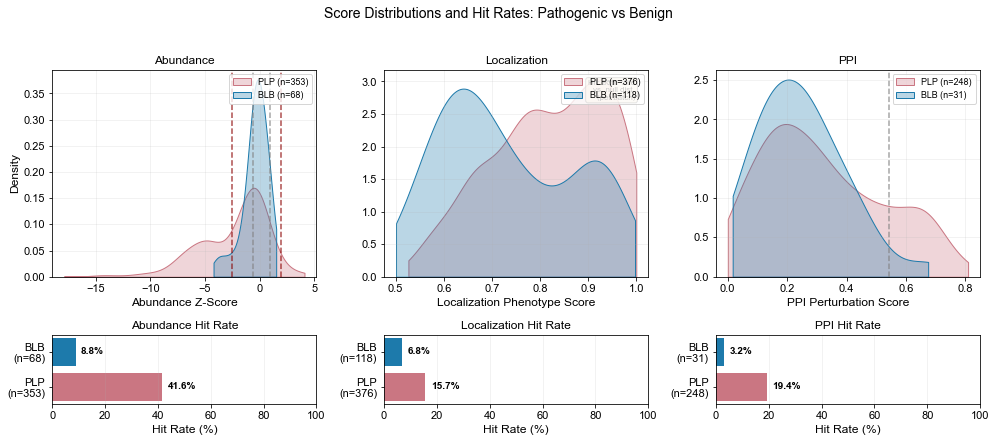

In [ ]:
# Filter for Benign and Pathogenic only
df_bp = al_dual_img_ppi_assayed_dedup.filter(
    pl.col("clinvar_clnsig_clean").is_in(["Pathogenic", "Benign"])
)

# Define assays and their properties
assays = [
    {"score": "dualipa_score", "hit": "dualipa_hit", "label": "Abundance Z-Score"},
    {"score": "imaging_score", "hit": "imaging_hit", "label": "Localization Phenotype Score"},
    {"score": "ppi_score", "hit": "ppi_hit", "label": "PPI Perturbation Score"}
]

fig, axes = plt.subplots(2, 3, figsize=(14, 6),
    gridspec_kw={'height_ratios': [3, 1]}  # First row 3x taller than second row
)

categories = ["Pathogenic", "Benign"]
colors = {
    "Pathogenic": palette_dict["clinvar_clnsig_clean"]["Pathogenic"],
    "Benign": palette_dict["clinvar_clnsig_clean"]["Benign"]
}

cat_names = {
    "Pathogenic": "PLP",
    "Benign": "BLB"}

data_limits = {
    "dualipa_score": (al_dual_img_ppi_assayed_dedup['dualipa_score'].min(), al_dual_img_ppi_assayed_dedup['dualipa_score'].max()),
    "imaging_score": (al_dual_img_ppi_assayed_dedup['imaging_score'].min(), al_dual_img_ppi_assayed_dedup['imaging_score'].max()),
    "ppi_score": (al_dual_img_ppi_assayed_dedup['ppi_score'].min(), al_dual_img_ppi_assayed_dedup['ppi_score'].max())
}

# Row 1: KDE distributions
for i, assay in enumerate(assays):
    ax = axes[0, i]
    for cat in categories:
        data = df_bp.filter(
            pl.col("clinvar_clnsig_clean") == cat,
            pl.col(assay["score"]).is_not_null()
        )[assay["score"]].to_numpy()
        
        if len(data) > 0:
            sns.kdeplot(
                data=data,
                ax=ax,
                color=colors[cat],
                label=f"{cat_names[cat]} (n={len(data)})",
                linewidth=1,
                fill=True,
                alpha=0.3,
                # cut=0,
                # clip=data_limits[assay['score']]  # Explicitly restrict to data range
                clip=(data.min(),data.max())  # Explicitly restrict to data range
            )
    
    # Add threshold lines based on assay type
    if i == 0:  # DUAL-IPA - has score thresholds
        ax.axvline(x=benign_thres_bottom, color='gray', linestyle='--', alpha=0.7, linewidth=1.5)
        ax.axvline(x=benign_thres_top, color='gray', linestyle='--', alpha=0.7, linewidth=1.5)
        ax.axvline(x=path_thres, color='darkred', linestyle='--', alpha=0.7, linewidth=1.5)
        ax.axvline(x=path_thres_2, color='darkred', linestyle='--', alpha=0.7, linewidth=1.5)
    elif i == 1:  # Imaging - no simple threshold
        ax.text(0.95, 0.95, "Hit: 95th %ile\nvs. null dist.\n(per batch)", 
                transform=ax.transAxes, fontsize=8, va='top', ha='right',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    elif i == 2:  # PPI - has score threshold
        ax.axvline(x=ppi_threshold, color='gray', linestyle='--', alpha=0.7, linewidth=1.5)
    
    ax.set_xlabel(assay["label"])
    ax.set_ylabel("Density" if i == 0 else "")
    ax.set_title(assay["label"].split()[0])
    ax.legend(loc="upper right", fontsize=9)
    ax.grid(alpha=0.2)

# Row 2: Hit rate bar plots
for i, assay in enumerate(assays):
    ax = axes[1, i]
    
    hit_rates = []
    counts = []
    bar_colors = []
    for cat in categories:
        subset = df_bp.filter(
            pl.col("clinvar_clnsig_clean") == cat,
            pl.col(assay["hit"]).is_not_null()
        )
        total = subset.shape[0]
        hits = subset.filter(pl.col(assay["hit"])).shape[0]
        hit_rate = (hits / total * 100) if total > 0 else 0
        hit_rates.append(hit_rate)
        counts.append(total)
        bar_colors.append(colors[cat])  # Use category-specific color
    
    y_pos = range(len(categories))
    
    # Background bars (100%)
    # ax.barh(y_pos, [100, 100], color='#00A3A3', alpha=0.8, label="Non-hit")
    # Hit bars
    bars = ax.barh(y_pos, hit_rates, color=bar_colors, label="Hit")
    
    # Annotations
    for j, (rate, count) in enumerate(zip(hit_rates, counts)):
        ax.text(rate + 2, j, f"{rate:.1f}%", va='center', fontweight='bold', fontsize=10)
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels([f"{cat_names[cat]}\n(n={n})" for cat, n in zip(categories, counts)])
    ax.set_xlabel("Hit Rate (%)")
    ax.set_xlim(0, 100)
    ax.set_title(f"{assay['label'].split()[0]} Hit Rate")
    ax.grid(axis='x', alpha=0.2)
    
    # if i == 2:
        # ax.legend(loc='lower right', fontsize=9)

plt.suptitle("Score Distributions and Hit Rates: Pathogenic vs Benign", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

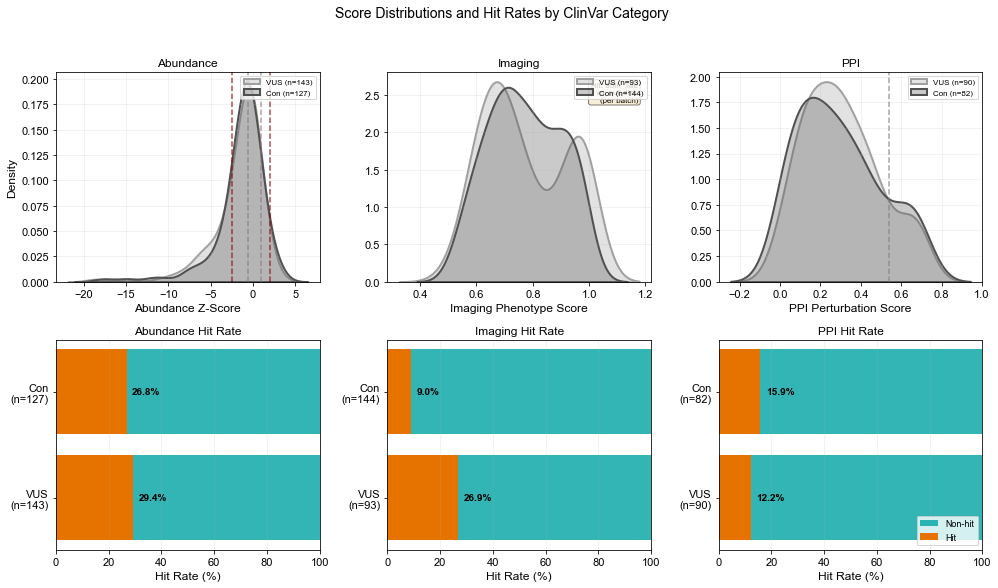

In [ ]:
# Filter for all 4 categories
df_all = al_dual_img_ppi_assayed_dedup.filter(
    pl.col("clinvar_clnsig_clean").is_in(["VUS", "Conflicting"])
)

# Define assays and their properties
assays = [
    {"score": "dualipa_score", "hit": "dualipa_hit", "label": "Abundance Z-Score"},
    {"score": "imaging_score", "hit": "imaging_hit", "label": "Imaging Phenotype Score"},
    {"score": "ppi_score", "hit": "ppi_hit", "label": "PPI Perturbation Score"}
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

categories = ["VUS", "Conflicting"]
colors = {
    "Pathogenic": palette_dict["clinvar_clnsig_clean"]["Pathogenic"],
    "Benign": palette_dict["clinvar_clnsig_clean"]["Benign"],
    "VUS": palette_dict["clinvar_clnsig_clean"]["VUS"],
    "Conflicting": palette_dict["clinvar_clnsig_clean"]["Conflicting"]
}

# Row 1: KDE distributions
for i, assay in enumerate(assays):
    ax = axes[0, i]
    for cat in categories:
        data = df_all.filter(
            pl.col("clinvar_clnsig_clean") == cat,
            pl.col(assay["score"]).is_not_null()
        )[assay["score"]].to_numpy()
        
        if len(data) > 0:
            sns.kdeplot(
                data=data,
                ax=ax,
                color=colors[cat],
                label=f"{cat[:3]} (n={len(data)})",
                linewidth=2,
                fill=True,
                alpha=0.3
            )
    
    # Add threshold lines based on assay type
    if i == 0:  # DUAL-IPA - has score thresholds
        ax.axvline(x=benign_thres_bottom, color='gray', linestyle='--', alpha=0.7, linewidth=1.5)
        ax.axvline(x=benign_thres_top, color='gray', linestyle='--', alpha=0.7, linewidth=1.5)
        ax.axvline(x=path_thres, color='darkred', linestyle='--', alpha=0.7, linewidth=1.5)
        ax.axvline(x=path_thres_2, color='darkred', linestyle='--', alpha=0.7, linewidth=1.5)
    elif i == 1:  # Imaging - no simple threshold
        ax.text(0.95, 0.95, "Hit: 95th %ile\nvs. null dist.\n(per batch)", 
                transform=ax.transAxes, fontsize=8, va='top', ha='right',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))
    elif i == 2:  # PPI - has score threshold
        ax.axvline(x=ppi_threshold, color='gray', linestyle='--', alpha=0.7, linewidth=1.5)
    
    ax.set_xlabel(assay["label"])
    ax.set_ylabel("Density" if i == 0 else "")
    ax.set_title(assay["label"].split()[0])
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(alpha=0.2)

# Row 2: Hit rate bar plots
for i, assay in enumerate(assays):
    ax = axes[1, i]
    
    hit_rates = []
    counts = []
    for cat in categories:
        subset = df_all.filter(
            pl.col("clinvar_clnsig_clean") == cat,
            pl.col(assay["hit"]).is_not_null()
        )
        total = subset.shape[0]
        hits = subset.filter(pl.col(assay["hit"])).shape[0]
        hit_rate = (hits / total * 100) if total > 0 else 0
        hit_rates.append(hit_rate)
        counts.append(total)
    
    y_pos = range(len(categories))
    
    # Background bars (100%)
    ax.barh(y_pos, [100] * len(categories), color='#00A3A3', alpha=0.8, label="Non-hit")
    # Hit bars
    bars = ax.barh(y_pos, hit_rates, color='#E67300', label="Hit")
    
    # Annotations
    for j, (rate, count) in enumerate(zip(hit_rates, counts)):
        ax.text(rate + 2, j, f"{rate:.1f}%", va='center', fontweight='bold', fontsize=10)
    
    ax.set_yticks(y_pos)
    ax.set_yticklabels([f"{cat[:3]}\n(n={n})" for cat, n in zip(categories, counts)])
    ax.set_xlabel("Hit Rate (%)")
    ax.set_xlim(0, 100)
    ax.set_title(f"{assay['label'].split()[0]} Hit Rate")
    ax.grid(axis='x', alpha=0.2)
    
    if i == 2:
        ax.legend(loc='lower right', fontsize=9)

plt.suptitle("Score Distributions and Hit Rates by ClinVar Category", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

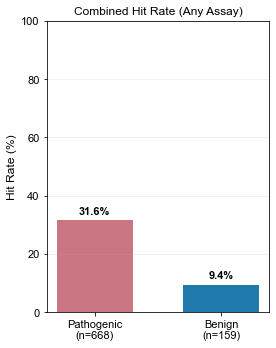

Fisher's exact test: OR=4.43, p=1.61e-09


In [ ]:
# Filter for Benign and Pathogenic only
df_bp = al_dual_img_ppi_assayed_dedup.filter(
    pl.col("clinvar_clnsig_clean").is_in(["Pathogenic", "Benign"])
).with_columns(
    # A variant is a hit if ANY of the 3 assays shows a hit
    pl.when(
        (pl.col("dualipa_hit") == True) | 
        (pl.col("imaging_hit") == True) | 
        (pl.col("ppi_hit") == True)
    )
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("any_assay_hit")
)

fig, ax = plt.subplots(1, 1, figsize=(4, 5))

categories = ["Pathogenic", "Benign"]
colors = {
    "Pathogenic": palette_dict["clinvar_clnsig_clean"]["Pathogenic"],  # red
    "Benign": palette_dict["clinvar_clnsig_clean"]["Benign"]  # blue
}

hit_rates = []
counts = []
for cat in categories:
    subset = df_bp.filter(pl.col("clinvar_clnsig_clean") == cat)
    total = subset.shape[0]
    hits = subset.filter(pl.col("any_assay_hit")).shape[0]
    hit_rate = (hits / total * 100) if total > 0 else 0
    hit_rates.append(hit_rate)
    counts.append(total)

x_pos = range(len(categories))

# Background bars (100%)
# ax.bar(x_pos, [100, 100], color='lightgrey', alpha=0.5, label="Non-hit", width=0.6)
# Hit bars with category-specific colors
bars = ax.bar(x_pos, hit_rates, color=[colors[cat] for cat in categories], width=0.6, label="Hit")

# Annotations
for j, (rate, count) in enumerate(zip(hit_rates, counts)):
    ax.text(j, rate + 2, f"{rate:.1f}%", ha='center', fontweight='bold', fontsize=11)

ax.set_xticks(x_pos)
ax.set_xticklabels([f"{cat}\n(n={n})" for cat, n in zip(categories, counts)])
ax.set_ylabel("Hit Rate (%)")
ax.set_ylim(0, 100)
ax.set_title("Combined Hit Rate (Any Assay)")
ax.grid(axis='y', alpha=0.2)

plt.tight_layout()
# plt.savefig("../4_manuscript_figures/hit_rates_any_assay_pathogenic_benign_vertical.svg", 
#             format='svg', dpi=400, bbox_inches='tight', transparent=True)
plt.show()

# Print Fisher's exact test
contingency_table = df_bp.group_by(
    ["any_assay_hit", 'clinvar_clnsig_clean']
).agg(
    pl.len()
).pivot(
    index="any_assay_hit",
    on='clinvar_clnsig_clean',
    values="len"
).sort(
    "any_assay_hit", descending=True
)
table = contingency_table.select(["Pathogenic", "Benign"]).to_numpy()
odds_ratio, p_value = fisher_exact(table, alternative='two-sided')
print(f"Fisher's exact test: OR={odds_ratio:.2f}, p={p_value:.2e}")

In [ ]:
# Get Benign variants that are hits in any assay
benign_hits = al_dual_img_ppi_assayed_dedup.filter(
    pl.col("clinvar_clnsig_clean") == "Benign",
    (pl.col("dualipa_hit") == True) | 
    (pl.col("imaging_hit") == True) | 
    (pl.col("ppi_hit") == True)
).select([
    "symbol",
    "gene_variant",
    "aa_change",
    "clinvar_clnsig_clean",
    "dualipa_score",
    "dualipa_hit",
    "imaging_score", 
    "imaging_hit",
    "ppi_score",
    "ppi_hit"
]).sort("symbol", "gene_variant")

print(f"Benign variants with hits in any assay: {benign_hits.shape[0]}")
display(benign_hits)

# Optionally save to file
benign_hits.write_csv("../3_outputs/benign_variants_any_assay_hits.tsv", separator="\t")

Benign variants with hits in any assay: 15


symbol,gene_variant,aa_change,clinvar_clnsig_clean,dualipa_score,dualipa_hit,imaging_score,imaging_hit,ppi_score,ppi_hit
str,str,str,str,f64,bool,f64,bool,f64,bool
"""AGXT""","""AGXT_Arg197Gln""","""Arg197Gln""","""Benign""",-4.219288,true,0.684923,false,0.091309,false
"""BRCA1""","""BRCA1_Ala102Gly""","""Ala102Gly""","""Benign""",null,null,0.967622,true,null,null
"""EFHC1""","""EFHC1_Pro77Thr""","""Pro77Thr""","""Benign""",-3.231165,true,null,null,null,null
"""GFAP""","""GFAP_Asp295Asn""","""Asp295Asn""","""Benign""",-2.598018,true,null,null,null,null
"""KCNJ2""","""KCNJ2_Ile258Thr""","""Ile258Thr""","""Benign""",-1.59732,false,null,null,0.674365,true
…,…,…,…,…,…,…,…,…,…
"""MLH1""","""MLH1_Lys618Arg""","""Lys618Arg""","""Benign""",null,null,0.910775,true,null,null
"""MLH1""","""MLH1_Lys751Arg""","""Lys751Arg""","""Benign""",null,null,0.88706,true,0.202487,false
"""MSH2""","""MSH2_Arg96His""","""Arg96His""","""Benign""",-3.857116,true,null,null,null,null


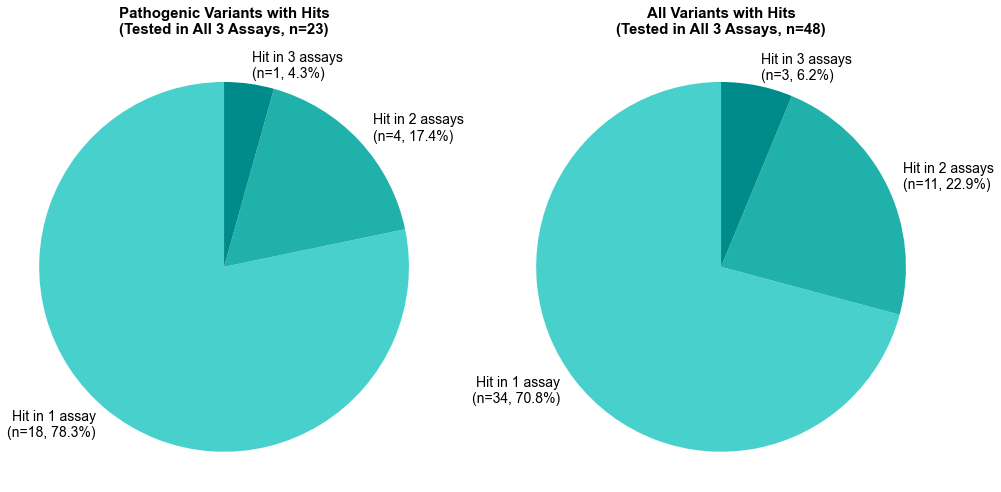


Pathogenic variants tested in all 3 assays with at least 1 hit: 23
All variants tested in all 3 assays with at least 1 hit: 48


In [ ]:
# Create side-by-side pie charts for Pathogenic vs All variants
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

# Colors - gradient from light to dark orange
# colors = ['#FFB366', '#E67300', '#994D00']
colors = ['#48D1CC', '#20B2AA', '#008B8B']  # Medium turquoise → Light sea green → Dark cyan

# --- LEFT: Pathogenic variants only ---
df_path_3assays_patho = al_dual_img_ppi_assayed_dedup.filter(
    pl.col("clinvar_clnsig_clean") == "Pathogenic",
    pl.col("dualipa_score").is_not_null(),
    pl.col("imaging_score").is_not_null(),
    pl.col("ppi_score").is_not_null()
).with_columns(
    pl.sum_horizontal(
        pl.col("dualipa_hit").fill_null(False),
        pl.col("imaging_hit").fill_null(False),
        pl.col("ppi_hit").fill_null(False),
    ).alias("num_assays_hit")
).filter(
    pl.col("num_assays_hit") >= 1
)

hit_counts_patho = df_path_3assays_patho.group_by("num_assays_hit").agg(
    pl.len().alias("count")
).sort("num_assays_hit").to_pandas()

total_patho = hit_counts_patho["count"].sum()
hit_counts_patho["percentage"] = (hit_counts_patho["count"] / total_patho * 100).round(1)

labels_patho = [f"Hit in {int(n)} assay{'s' if n > 1 else ''}\n(n={c}, {p}%)" 
                for n, c, p in zip(hit_counts_patho["num_assays_hit"], 
                                   hit_counts_patho["count"], 
                                   hit_counts_patho["percentage"])]

axes[0].pie(
    hit_counts_patho["count"], 
    labels=labels_patho,
    colors=colors[:len(hit_counts_patho)],
    autopct="",
    startangle=90,
    textprops={'fontsize': 14}
)
axes[0].set_title(f"Pathogenic Variants with Hits\n(Tested in All 3 Assays, n={total_patho})", 
                  fontsize=15, fontweight='bold', pad=15)
axes[0].axis('equal')

# --- RIGHT: All variants ---
df_path_3assays_all = al_dual_img_ppi_assayed_dedup.filter(
    pl.col("dualipa_score").is_not_null(),
    pl.col("imaging_score").is_not_null(),
    pl.col("ppi_score").is_not_null()
).with_columns(
    pl.sum_horizontal(
        pl.col("dualipa_hit").fill_null(False),
        pl.col("imaging_hit").fill_null(False),
        pl.col("ppi_hit").fill_null(False),
    ).alias("num_assays_hit")
).filter(
    pl.col("num_assays_hit") >= 1
)

hit_counts_all = df_path_3assays_all.group_by("num_assays_hit").agg(
    pl.len().alias("count")
).sort("num_assays_hit").to_pandas()

total_all = hit_counts_all["count"].sum()
hit_counts_all["percentage"] = (hit_counts_all["count"] / total_all * 100).round(1)

labels_all = [f"Hit in {int(n)} assay{'s' if n > 1 else ''}\n(n={c}, {p}%)" 
              for n, c, p in zip(hit_counts_all["num_assays_hit"], 
                                 hit_counts_all["count"], 
                                 hit_counts_all["percentage"])]

axes[1].pie(
    hit_counts_all["count"], 
    labels=labels_all,
    colors=colors[:len(hit_counts_all)],
    autopct="",
    startangle=90,
    textprops={'fontsize': 14}
)
axes[1].set_title(f"All Variants with Hits\n(Tested in All 3 Assays, n={total_all})", 
                  fontsize=15, fontweight='bold', pad=15)
axes[1].axis('equal')

plt.tight_layout()
# plt.savefig("../4_manuscript_figures/hit_distribution_3assays_combined.svg", dpi=400, bbox_inches='tight', transparent=True)
plt.show()

# Print summaries
print(f"\nPathogenic variants tested in all 3 assays with at least 1 hit: {total_patho}")
print(f"All variants tested in all 3 assays with at least 1 hit: {total_all}")

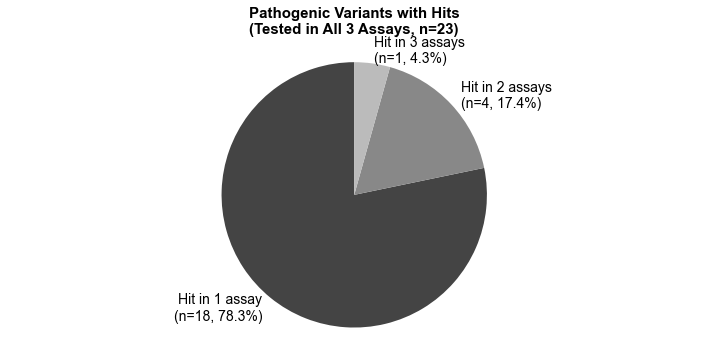


Pathogenic variants tested in all 3 assays with at least 1 hit: 23
All variants tested in all 3 assays with at least 1 hit: 48


In [ ]:
# Create side-by-side pie charts for Pathogenic vs All variants
fig, ax = plt.subplots(figsize=(10, 5))

# Colors - gradient from light to dark orange
# colors = ['#FFB366', '#E67300', '#994D00']
colors = ['#48D1CC', '#20B2AA', '#008B8B']  # Medium turquoise → Light sea green → Dark cyan
colors = list(reversed(['#bbbbbb', '#888888', '#444444']))  # Light grey → Medium grey → Dark grey

# --- LEFT: Pathogenic variants only ---
df_path_3assays_patho = al_dual_img_ppi_assayed_dedup.filter(
    pl.col("clinvar_clnsig_clean") == "Pathogenic",
    pl.col("dualipa_score").is_not_null(),
    pl.col("imaging_score").is_not_null(),
    pl.col("ppi_score").is_not_null()
).with_columns(
    pl.sum_horizontal(
        pl.col("dualipa_hit").fill_null(False),
        pl.col("imaging_hit").fill_null(False),
        pl.col("ppi_hit").fill_null(False),
    ).alias("num_assays_hit")
).filter(
    pl.col("num_assays_hit") >= 1
)

hit_counts_patho = df_path_3assays_patho.group_by("num_assays_hit").agg(
    pl.len().alias("count")
).sort("num_assays_hit").to_pandas()

total_patho = hit_counts_patho["count"].sum()
hit_counts_patho["percentage"] = (hit_counts_patho["count"] / total_patho * 100).round(1)

labels_patho = [f"Hit in {int(n)} assay{'s' if n > 1 else ''}\n(n={c}, {p}%)" 
                for n, c, p in zip(hit_counts_patho["num_assays_hit"], 
                                   hit_counts_patho["count"], 
                                   hit_counts_patho["percentage"])]

ax.pie(
    hit_counts_patho["count"], 
    labels=labels_patho,
    colors=colors[:len(hit_counts_patho)],
    autopct="",
    startangle=90,
    textprops={'fontsize': 14}
)
ax.set_title(f"Pathogenic Variants with Hits\n(Tested in All 3 Assays, n={total_patho})", 
                  fontsize=15, fontweight='bold', pad=15)
ax.axis('equal')

plt.tight_layout()
# plt.savefig("../4_manuscript_figures/hit_distribution_3assays_combined.svg", dpi=400, bbox_inches='tight', transparent=True)
plt.show()

# Print summaries
print(f"\nPathogenic variants tested in all 3 assays with at least 1 hit: {total_patho}")
print(f"All variants tested in all 3 assays with at least 1 hit: {total_all}")

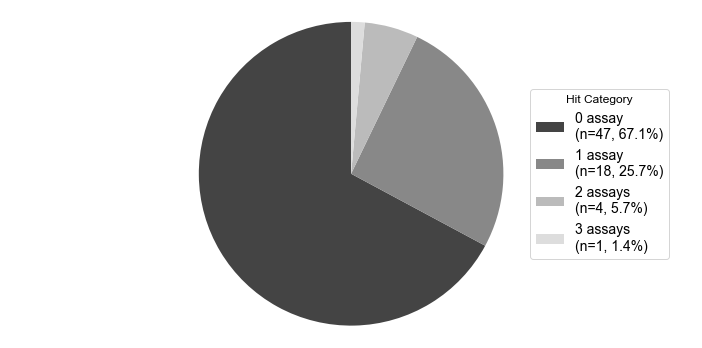


Pathogenic variants tested in all 3 assays with at least 1 hit: 70
All variants tested in all 3 assays with at least 1 hit: 48


In [ ]:
# Create side-by-side pie charts for Pathogenic vs All variants
fig, ax = plt.subplots(figsize=(10, 5))

# Colors - gradient from light to dark orange
# colors = ['#FFB366', '#E67300', '#994D00']
colors = ['#48D1CC', '#20B2AA', '#008B8B']  # Medium turquoise → Light sea green → Dark cyan
colors = ['#bbbbbb', '#888888', '#444444']  # Light grey → Medium grey → Dark grey
# 4-level greyscale: light to dark
colors = list(reversed(['#dddddd', '#bbbbbb', '#888888', '#444444']))
# --- LEFT: Pathogenic variants only ---
df_path_3assays_patho = al_dual_img_ppi_assayed_dedup.filter(
    pl.col("clinvar_clnsig_clean") == "Pathogenic",
    pl.col("dualipa_score").is_not_null(),
    pl.col("imaging_score").is_not_null(),
    pl.col("ppi_score").is_not_null()
).with_columns(
    pl.sum_horizontal(
        pl.col("dualipa_hit").fill_null(False),
        pl.col("imaging_hit").fill_null(False),
        pl.col("ppi_hit").fill_null(False),
    ).alias("num_assays_hit")
)#.filter(
#    pl.col("num_assays_hit") >= 1
#)

hit_counts_patho = df_path_3assays_patho.group_by("num_assays_hit").agg(
    pl.len().alias("count")
).sort("num_assays_hit").to_pandas()

total_patho = hit_counts_patho["count"].sum()
hit_counts_patho["percentage"] = (hit_counts_patho["count"] / total_patho * 100).round(1)

labels_patho = [f"{int(n)} assay{'s' if n > 1 else ''}\n(n={c}, {p}%)" 
                for n, c, p in zip(hit_counts_patho["num_assays_hit"], 
                                   hit_counts_patho["count"], 
                                   hit_counts_patho["percentage"])]

wedges, texts, autotexts = ax.pie(
    hit_counts_patho["count"], 
    labels=None,  # No labels on pie
    colors=colors[:len(hit_counts_patho)],
    autopct="",
    startangle=90
)
ax.legend(wedges, labels_patho, title="Hit Category", loc="center left", bbox_to_anchor=(0.75, 0.5), fontsize=14)


# ax.set_title(f"Pathogenic Variants with Hits\n(Tested in All 3 Assays, n={total_patho})", 
                #   fontsize=15, fontweight='bold', pad=15)
ax.axis('equal')

plt.tight_layout()
# plt.savefig("../4_manuscript_figures/hit_distribution_3assays_combined.svg", dpi=400, bbox_inches='tight', transparent=True)
plt.show()

# Print summaries
print(f"\nPathogenic variants tested in all 3 assays with at least 1 hit: {total_patho}")
print(f"All variants tested in all 3 assays with at least 1 hit: {total_all}")

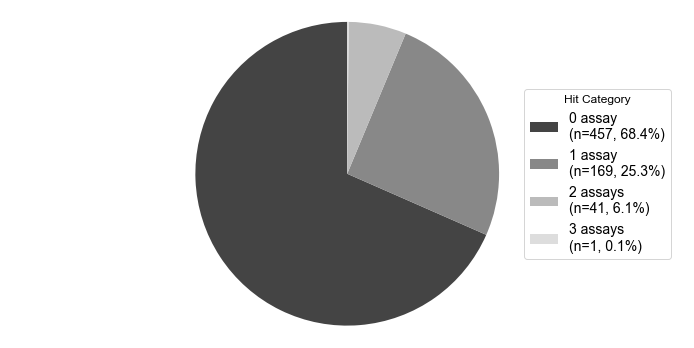


Pathogenic variants tested in all 3 assays with at least 1 hit: 668
All variants tested in all 3 assays with at least 1 hit: 48


In [ ]:
# Create side-by-side pie charts for Pathogenic vs All variants
fig, ax = plt.subplots(figsize=(10, 5))

# Colors - gradient from light to dark orange
# colors = ['#FFB366', '#E67300', '#994D00']
colors = ['#48D1CC', '#20B2AA', '#008B8B']  # Medium turquoise → Light sea green → Dark cyan
colors = ['#bbbbbb', '#888888', '#444444']  # Light grey → Medium grey → Dark grey
# 4-level greyscale: light to dark
colors = list(reversed(['#dddddd', '#bbbbbb', '#888888', '#444444']))
# --- LEFT: Pathogenic variants only ---
df_path_3assays_patho = al_dual_img_ppi_assayed_dedup.filter(
    pl.col("clinvar_clnsig_clean") == "Pathogenic").filter(
    (pl.col("dualipa_score").is_not_null()) |
    (pl.col("imaging_score").is_not_null()) |
    pl.col("ppi_score").is_not_null()
).with_columns(
    pl.sum_horizontal(
        pl.col("dualipa_hit").fill_null(False),
        pl.col("imaging_hit").fill_null(False),
        pl.col("ppi_hit").fill_null(False),
    ).alias("num_assays_hit")
)#.filter(
#    pl.col("num_assays_hit") >= 1
#)

hit_counts_patho = df_path_3assays_patho.group_by("num_assays_hit").agg(
    pl.len().alias("count")
).sort("num_assays_hit").to_pandas()

total_patho = hit_counts_patho["count"].sum()
hit_counts_patho["percentage"] = (hit_counts_patho["count"] / total_patho * 100).round(1)

labels_patho = [f"{int(n)} assay{'s' if n > 1 else ''}\n(n={c}, {p}%)" 
                for n, c, p in zip(hit_counts_patho["num_assays_hit"], 
                                   hit_counts_patho["count"], 
                                   hit_counts_patho["percentage"])]

wedges, texts, autotexts = ax.pie(
    hit_counts_patho["count"], 
    labels=None,  # No labels on pie
    colors=colors[:len(hit_counts_patho)],
    autopct="",
    startangle=90
)
ax.legend(wedges, labels_patho, title="Hit Category", loc="center left", bbox_to_anchor=(0.75, 0.5), fontsize=14)


# ax.set_title(f"Pathogenic Variants with Hits\n(Tested in All 3 Assays, n={total_patho})", 
                #   fontsize=15, fontweight='bold', pad=15)
ax.axis('equal')

plt.tight_layout()
# plt.savefig("../4_manuscript_figures/hit_distribution_3assays_combined.svg", dpi=400, bbox_inches='tight', transparent=True)
plt.show()

# Print summaries
print(f"\nPathogenic variants tested in all 3 assays with at least 1 hit: {total_patho}")
print(f"All variants tested in all 3 assays with at least 1 hit: {total_all}")

In [ ]:
import polars as pl
import scipy.stats as stats

def run_pairwise_fisher(df, label="Variants"):
    """
    Runs Fisher's Exact Test for all 3 pairs of assays.
    Applies Bonferroni correction (alpha = 0.05 / 3 = 0.017)
    """
    # Filter for valid data (tested in all 3)
    valid_df = df.filter(
        pl.col("dualipa_score").is_not_null(),
        pl.col("imaging_score").is_not_null(),
        pl.col("ppi_score").is_not_null()
    )
    
    n_total = len(valid_df)
    print(f"\n=== PAIRWISE FISHER TESTS: {label} (n={n_total}) ===")
    
    # Define the 3 pairs
    pairs = [
        ("dualipa_hit", "imaging_hit", "Dualipa vs Imaging"),
        ("dualipa_hit", "ppi_hit",     "Dualipa vs PPI"),
        ("imaging_hit", "ppi_hit",     "Imaging vs PPI")
    ]
    
    for col1, col2, name in pairs:
        # Construct 2x2 Contingency Table
        #           | Col2+ | Col2- |
        # ---------------------------
        # Col1+     |   a   |   b   |
        # Col1-     |   c   |   d   |
        
        # a: Both Positive
        a = valid_df.filter((pl.col(col1).fill_null(False)) & (pl.col(col2).fill_null(False))).height
        # b: Col1 Pos, Col2 Neg
        b = valid_df.filter((pl.col(col1).fill_null(False)) & (~pl.col(col2).fill_null(False))).height
        # c: Col1 Neg, Col2 Pos
        c = valid_df.filter((~pl.col(col1).fill_null(False)) & (pl.col(col2).fill_null(False))).height
        # d: Both Negative
        d = valid_df.filter((~pl.col(col1).fill_null(False)) & (~pl.col(col2).fill_null(False))).height
        
        # Fisher's Exact Test
        odds_ratio, p_value = stats.fisher_exact([[a, b], [c, d]], alternative='two-sided')
        
        # Bonferroni Threshold (0.05 / 3 tests = 0.0167)
        significance = "SIGNIFICANT" if p_value < 0.0167 else "Not sig"
        
        print(f"\n--- {name} ---")
        print(f"Table: [[{a}, {b}], [{c}, {d}]] (Both+, 1+2-, 1-2+, Both-)")
        print(f"Odds Ratio: {odds_ratio:.2f}")
        print(f"P-Value:    {p_value:.4e} ({significance})")

# --- EXECUTE ---

# 1. Pathogenic Variants
df_patho = al_dual_img_ppi_assayed_dedup.filter(pl.col("clinvar_clnsig_clean") == "Pathogenic")
run_pairwise_fisher(df_patho, label="Pathogenic")

# 2. All Variants
run_pairwise_fisher(al_dual_img_ppi_assayed_dedup, label="All Variants")


=== PAIRWISE FISHER TESTS: Pathogenic (n=70) ===

--- Dualipa vs Imaging ---
Table: [[5, 13], [2, 50]] (Both+, 1+2-, 1-2+, Both-)
Odds Ratio: 9.62
P-Value:    1.0309e-02 (SIGNIFICANT)

--- Dualipa vs PPI ---
Table: [[1, 17], [3, 49]] (Both+, 1+2-, 1-2+, Both-)
Odds Ratio: 0.96
P-Value:    1.0000e+00 (Not sig)

--- Imaging vs PPI ---
Table: [[1, 6], [3, 60]] (Both+, 1+2-, 1-2+, Both-)
Odds Ratio: 3.33
P-Value:    3.5035e-01 (Not sig)

=== PAIRWISE FISHER TESTS: All Variants (n=151) ===

--- Dualipa vs Imaging ---
Table: [[12, 28], [4, 107]] (Both+, 1+2-, 1-2+, Both-)
Odds Ratio: 11.46
P-Value:    2.3669e-05 (SIGNIFICANT)

--- Dualipa vs PPI ---
Table: [[5, 35], [4, 107]] (Both+, 1+2-, 1-2+, Both-)
Odds Ratio: 3.82
P-Value:    5.5721e-02 (Not sig)

--- Imaging vs PPI ---
Table: [[3, 13], [6, 129]] (Both+, 1+2-, 1-2+, Both-)
Odds Ratio: 4.96
P-Value:    5.5539e-02 (Not sig)


In [ ]:
import polars as pl
import scipy.stats as stats

def run_pairwise_fisher(df, label="Variants"):
    """
    Runs Fisher's Exact Test for all 3 pairs of assays.
    Applies Bonferroni correction (alpha = 0.05 / 3 = 0.017)
    """
    # Filter for valid data (tested in all 3)
    valid_df = df.filter(
        (pl.col("dualipa_score").is_not_null()) |
        (pl.col("imaging_score").is_not_null()) |
        pl.col("ppi_score").is_not_null()
    )
    
    n_total = len(valid_df)
    print(f"\n=== PAIRWISE FISHER TESTS: {label} (n={n_total}) ===")
    
    # Define the 3 pairs
    pairs = [
        ("dualipa_hit", "imaging_hit", "Dualipa vs Imaging"),
        ("dualipa_hit", "ppi_hit",     "Dualipa vs PPI"),
        ("imaging_hit", "ppi_hit",     "Imaging vs PPI")
    ]
    
    for col1, col2, name in pairs:
        # Construct 2x2 Contingency Table
        #           | Col2+ | Col2- |
        # ---------------------------
        # Col1+     |   a   |   b   |
        # Col1-     |   c   |   d   |
        
        # a: Both Positive
        a = valid_df.filter((pl.col(col1).fill_null(False)) & (pl.col(col2).fill_null(False))).height
        # b: Col1 Pos, Col2 Neg
        b = valid_df.filter((pl.col(col1).fill_null(False)) & (~pl.col(col2).fill_null(False))).height
        # c: Col1 Neg, Col2 Pos
        c = valid_df.filter((~pl.col(col1).fill_null(False)) & (pl.col(col2).fill_null(False))).height
        # d: Both Negative
        d = valid_df.filter((~pl.col(col1).fill_null(False)) & (~pl.col(col2).fill_null(False))).height
        
        # Fisher's Exact Test
        odds_ratio, p_value = stats.fisher_exact([[a, b], [c, d]], alternative='two-sided')
        
        # Bonferroni Threshold (0.05 / 3 tests = 0.0167)
        significance = "SIGNIFICANT" if p_value < 0.0167 else "Not sig"
        
        print(f"\n--- {name} ---")
        print(f"Table: [[{a}, {b}], [{c}, {d}]] (Both+, 1+2-, 1-2+, Both-)")
        print(f"Odds Ratio: {odds_ratio:.2f}")
        print(f"P-Value:    {p_value:.4e} ({significance})")

# --- EXECUTE ---

# 1. Pathogenic Variants
df_patho = al_dual_img_ppi_assayed_dedup.filter(pl.col("clinvar_clnsig_clean") == "Pathogenic")
run_pairwise_fisher(df_patho, label="Pathogenic")

# 2. All Variants
run_pairwise_fisher(al_dual_img_ppi_assayed_dedup, label="All Variants")


=== PAIRWISE FISHER TESTS: Pathogenic (n=668) ===

--- Dualipa vs Imaging ---
Table: [[14, 133], [45, 476]] (Both+, 1+2-, 1-2+, Both-)
Odds Ratio: 1.11
P-Value:    7.4280e-01 (Not sig)

--- Dualipa vs PPI ---
Table: [[28, 119], [20, 501]] (Both+, 1+2-, 1-2+, Both-)
Odds Ratio: 5.89
P-Value:    1.3470e-08 (SIGNIFICANT)

--- Imaging vs PPI ---
Table: [[2, 57], [46, 563]] (Both+, 1+2-, 1-2+, Both-)
Odds Ratio: 0.43
P-Value:    3.0078e-01 (Not sig)

=== PAIRWISE FISHER TESTS: All Variants (n=1407) ===

--- Dualipa vs Imaging ---
Table: [[29, 237], [92, 1049]] (Both+, 1+2-, 1-2+, Both-)
Odds Ratio: 1.40
P-Value:    1.4510e-01 (Not sig)

--- Dualipa vs PPI ---
Table: [[42, 224], [37, 1104]] (Both+, 1+2-, 1-2+, Both-)
Odds Ratio: 5.59
P-Value:    1.6774e-12 (SIGNIFICANT)

--- Imaging vs PPI ---
Table: [[6, 115], [73, 1213]] (Both+, 1+2-, 1-2+, Both-)
Odds Ratio: 0.87
P-Value:    1.0000e+00 (Not sig)


In [ ]:
def run_pairwise_fisher(df, label="Variants"):
    """
    Runs Fisher's Exact Test for all 3 pairs of assays.
    Applies Bonferroni correction (alpha = 0.05 / 3 = 0.017)
    Only includes variants tested in both compared assays.
    """
    pairs = [
        ("dualipa_score", "dualipa_hit", "imaging_score", "imaging_hit", "Dualipa vs Imaging"),
        ("dualipa_score", "dualipa_hit", "ppi_score", "ppi_hit", "Dualipa vs PPI"),
        ("imaging_score", "imaging_hit", "ppi_score", "ppi_hit", "Imaging vs PPI"),
    ]
    for score1, hit1, score2, hit2, name in pairs:
        # Only keep variants tested in BOTH assays
        valid_df = df.filter(
            pl.col(score1).is_not_null() & pl.col(score2).is_not_null()
        )
        n_total = len(valid_df)
        print(f"\n=== {name} (n={n_total}) ===")
        # a: Both Positive
        a = valid_df.filter((pl.col(hit1).fill_null(False)) & (pl.col(hit2).fill_null(False))).height
        # b: Col1 Pos, Col2 Neg
        b = valid_df.filter((pl.col(hit1).fill_null(False)) & (~pl.col(hit2).fill_null(False))).height
        # c: Col1 Neg, Col2 Pos
        c = valid_df.filter((~pl.col(hit1).fill_null(False)) & (pl.col(hit2).fill_null(False))).height
        # d: Both Negative
        d = valid_df.filter((~pl.col(hit1).fill_null(False)) & (~pl.col(hit2).fill_null(False))).height
        odds_ratio, p_value = stats.fisher_exact([[a, b], [c, d]], alternative='two-sided')
        significance = "SIGNIFICANT" if p_value < 0.0167 else "Not sig"
        print(f"Table: [[{a}, {b}], [{c}, {d}]] (Both+, 1+2-, 1-2+, Both-)")
        print(f"Odds Ratio: {odds_ratio:.2f}")
        print(f"P-Value:    {p_value:.4e} ({significance})")

In [ ]:
df_patho = al_dual_img_ppi_assayed_dedup.filter(pl.col("clinvar_clnsig_clean") == "Pathogenic")
run_pairwise_fisher(df_patho, label="Pathogenic")
# run_pairwise_fisher(al_dual_img_ppi_assayed_dedup, label="All Variants")


=== Dualipa vs Imaging (n=131) ===
Table: [[14, 21], [9, 87]] (Both+, 1+2-, 1-2+, Both-)
Odds Ratio: 6.44
P-Value:    1.4114e-04 (SIGNIFICANT)

=== Dualipa vs PPI (n=136) ===
Table: [[28, 26], [5, 77]] (Both+, 1+2-, 1-2+, Both-)
Odds Ratio: 16.58
P-Value:    1.2760e-09 (SIGNIFICANT)

=== Imaging vs PPI (n=112) ===
Table: [[2, 17], [4, 89]] (Both+, 1+2-, 1-2+, Both-)
Odds Ratio: 2.62
P-Value:    2.6864e-01 (Not sig)



=== DUAL-IPA vs Imaging (n=131) ===
Table: [[14, 21], [9, 87]] (Both+, 1+2-, 1-2+, Both-)
Odds Ratio: 6.44
P-Value:    1.4114e-04 (SIGNIFICANT)


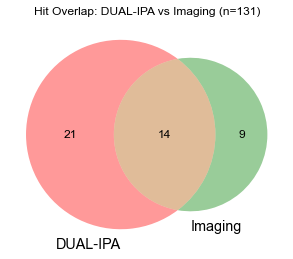


=== DUAL-IPA vs PPI (n=136) ===
Table: [[28, 26], [5, 77]] (Both+, 1+2-, 1-2+, Both-)
Odds Ratio: 16.58
P-Value:    1.2760e-09 (SIGNIFICANT)


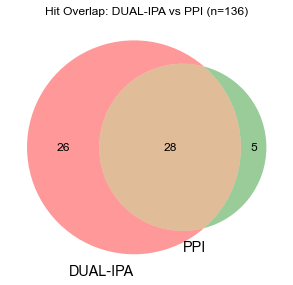


=== Imaging vs PPI (n=112) ===
Table: [[2, 17], [4, 89]] (Both+, 1+2-, 1-2+, Both-)
Odds Ratio: 2.62
P-Value:    2.6864e-01 (Not sig)


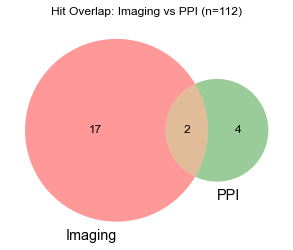

In [ ]:
from matplotlib_venn import venn2
import matplotlib.pyplot as plt
import scipy.stats as stats

def pairwise_fisher_and_venn(df, label="Variants"):
    """
    For each pair of assays:
      - Runs Fisher's Exact Test (only variants tested in both)
      - Plots Venn diagram of hit overlap
    """
    pairs = [
        ("dualipa_score", "dualipa_hit", "imaging_score", "imaging_hit", "DUAL-IPA", "Imaging"),
        ("dualipa_score", "dualipa_hit", "ppi_score", "ppi_hit", "DUAL-IPA", "PPI"),
        ("imaging_score", "imaging_hit", "ppi_score", "ppi_hit", "Imaging", "PPI"),
    ]
    
    if label == "Pathogenic":
        df = df.filter(pl.col("clinvar_clnsig_clean") == "Pathogenic")
    
    for score1, hit1, score2, hit2, name1, name2 in pairs:
        # Only keep variants tested in BOTH assays
        valid_df = df.filter(
            pl.col(score1).is_not_null() & pl.col(score2).is_not_null()
        )
        
        # print(valid_df.to_pandas().symbol.value_counts(normalize=True)*100)
        
        n_total = len(valid_df)
        print(f"\n=== {name1} vs {name2} (n={n_total}) ===")
        # a: Both Positive
        a = valid_df.filter((pl.col(hit1).fill_null(False)) & (pl.col(hit2).fill_null(False))).height
        # b: Col1 Pos, Col2 Neg
        b = valid_df.filter((pl.col(hit1).fill_null(False)) & (~pl.col(hit2).fill_null(False))).height
        # c: Col1 Neg, Col2 Pos
        c = valid_df.filter((~pl.col(hit1).fill_null(False)) & (pl.col(hit2).fill_null(False))).height
        # d: Both Negative
        d = valid_df.filter((~pl.col(hit1).fill_null(False)) & (~pl.col(hit2).fill_null(False))).height
        odds_ratio, p_value = stats.fisher_exact([[a, b], [c, d]], alternative='two-sided')
        significance = "SIGNIFICANT" if p_value < 0.0167 else "Not sig"
        print(f"Table: [[{a}, {b}], [{c}, {d}]] (Both+, 1+2-, 1-2+, Both-)")
        print(f"Odds Ratio: {odds_ratio:.2f}")
        print(f"P-Value:    {p_value:.4e} ({significance})")

        # Venn diagram of hits
        set1 = set(valid_df.filter(pl.col(hit1).fill_null(False))["gene_variant"].to_list())
        set2 = set(valid_df.filter(pl.col(hit2).fill_null(False))["gene_variant"].to_list())
        plt.figure(figsize=(5,5))
        venn2([set1, set2], set_labels=(name1, name2))
        plt.title(f"Hit Overlap: {name1} vs {name2} (n={n_total})")
        plt.show()

# Example usage:
pairwise_fisher_and_venn(df_patho, label="Pathogenic")


=== DUAL-IPA vs Imaging (n=131) ===
Table: [[14, 21], [9, 87]] (Both+, 1+2-, 1-2+, Both-)
Odds Ratio: 6.44
P-Value:    1.4114e-04 (SIGNIFICANT)


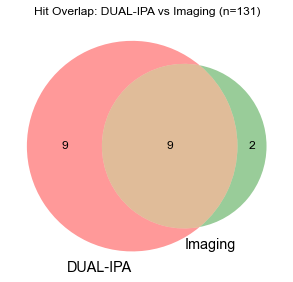


=== DUAL-IPA vs PPI (n=136) ===
Table: [[28, 26], [5, 77]] (Both+, 1+2-, 1-2+, Both-)
Odds Ratio: 16.58
P-Value:    1.2760e-09 (SIGNIFICANT)


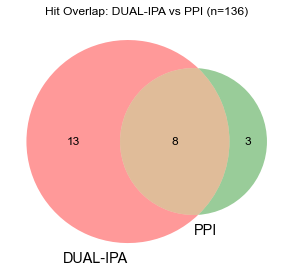


=== Imaging vs PPI (n=112) ===
Table: [[2, 17], [4, 89]] (Both+, 1+2-, 1-2+, Both-)
Odds Ratio: 2.62
P-Value:    2.6864e-01 (Not sig)


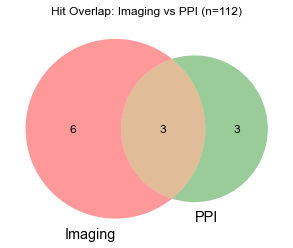

In [ ]:
from matplotlib_venn import venn2
import matplotlib.pyplot as plt
import scipy.stats as stats

def pairwise_fisher_and_venn(df, label="Variants"):
    """
    For each pair of assays:
      - Runs Fisher's Exact Test (only variants tested in both)
      - Plots Venn diagram of hit overlap
    """
    pairs = [
        ("dualipa_score", "dualipa_hit", "imaging_score", "imaging_hit", "DUAL-IPA", "Imaging"),
        ("dualipa_score", "dualipa_hit", "ppi_score", "ppi_hit", "DUAL-IPA", "PPI"),
        ("imaging_score", "imaging_hit", "ppi_score", "ppi_hit", "Imaging", "PPI"),
    ]
    
    if label == "Pathogenic":
        df = df.filter(pl.col("clinvar_clnsig_clean") == "Pathogenic")
    
    for score1, hit1, score2, hit2, name1, name2 in pairs:
        # Only keep variants tested in BOTH assays
        valid_df = df.filter(
            pl.col(score1).is_not_null() & pl.col(score2).is_not_null()
        )
        
        # print(valid_df.to_pandas().symbol.value_counts(normalize=True)*100)
        
        n_total = len(valid_df)
        print(f"\n=== {name1} vs {name2} (n={n_total}) ===")
        # a: Both Positive
        a = valid_df.filter((pl.col(hit1).fill_null(False)) & (pl.col(hit2).fill_null(False))).height
        # b: Col1 Pos, Col2 Neg
        b = valid_df.filter((pl.col(hit1).fill_null(False)) & (~pl.col(hit2).fill_null(False))).height
        # c: Col1 Neg, Col2 Pos
        c = valid_df.filter((~pl.col(hit1).fill_null(False)) & (pl.col(hit2).fill_null(False))).height
        # d: Both Negative
        d = valid_df.filter((~pl.col(hit1).fill_null(False)) & (~pl.col(hit2).fill_null(False))).height
        odds_ratio, p_value = stats.fisher_exact([[a, b], [c, d]], alternative='two-sided')
        significance = "SIGNIFICANT" if p_value < 0.0167 else "Not sig"
        print(f"Table: [[{a}, {b}], [{c}, {d}]] (Both+, 1+2-, 1-2+, Both-)")
        print(f"Odds Ratio: {odds_ratio:.2f}")
        print(f"P-Value:    {p_value:.4e} ({significance})")

        # Venn diagram of hits
        set1 = set(valid_df.filter(pl.col(hit1).fill_null(False))["symbol"].to_list())
        set2 = set(valid_df.filter(pl.col(hit2).fill_null(False))["symbol"].to_list())
        plt.figure(figsize=(5,5))
        venn2([set1, set2], set_labels=(name1, name2))
        plt.title(f"Hit Overlap: {name1} vs {name2} (n={n_total})")
        plt.show()

# Example usage:
pairwise_fisher_and_venn(df_patho, label="Pathogenic")

In [ ]:
df_patho.filter(
    (pl.col("dualipa_hit") == True) &
    (pl.col("ppi_hit") == True) 
).to_pandas().symbol.unique()

array(['HGD', 'KCNJ2', 'STXBP1', 'ASNS', 'NMNAT1', 'FBP1', 'MVK', 'SMAD3'],
      dtype=object)

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are se

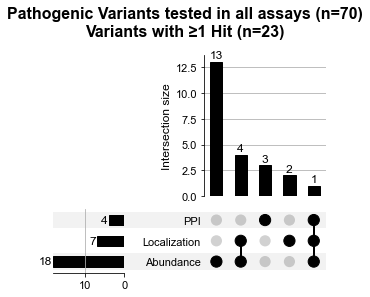

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are se

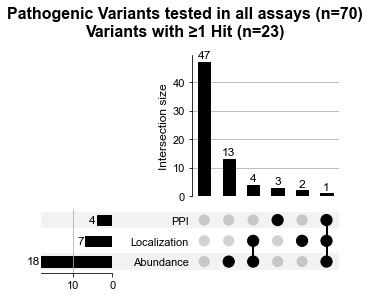

In [ ]:
import polars as pl
import matplotlib.pyplot as plt
from upsetplot import plot as upset_plot
from upsetplot import UpSet

def plot_upset_separate(df_raw):
    # --- Data Prep Function ---
    def prep_data_for_upset(df_input, filter_patho=False):
        valid_df = df_input.filter(
            pl.col("dualipa_score").is_not_null(),
            pl.col("imaging_score").is_not_null(),
            pl.col("ppi_score").is_not_null()
        )
        
        hit_df = valid_df.filter(
            pl.col("dualipa_hit").fill_null(False) |
            pl.col("imaging_hit").fill_null(False) |
            pl.col("ppi_hit").fill_null(False)
        )
        if filter_patho:
            valid_df = valid_df.filter(pl.col("clinvar_clnsig_clean") == "Pathogenic")
            hit_df = hit_df.filter(pl.col("clinvar_clnsig_clean") == "Pathogenic")
            title = f"Pathogenic Variants tested in all assays (n={len(valid_df)})\nVariants with ≥1 Hit (n={len(hit_df)})"
        else:
            title = f"All Variants (n={len(valid_df)})"

        # Convert to pandas boolean Series
        pdf = valid_df.select([
            pl.col("dualipa_hit").fill_null(False).alias("Abundance"),
            pl.col("imaging_hit").fill_null(False).alias("Localization"),
            pl.col("ppi_hit").fill_null(False).alias("PPI")
        ]).to_pandas()

        # Group by all 3 columns to get counts for UpSet
        upset_data = pdf.groupby(['Abundance', 'Localization', 'PPI']).size()
        return upset_data, title

    # --- Plot 1: Pathogenic Variants ---
    upset_patho, title_patho = prep_data_for_upset(df_raw, filter_patho=True)
    
    # Create a dedicated figure for Pathogenic
    fig1 = plt.figure(figsize=(10, 6))
    upset = UpSet(upset_patho, 
                  sort_by='cardinality', 
                  show_counts=True, 
                  totals_plot_elements=3,
                  min_degree=1)  # Hide side bars
    
    # render into the specific figure
    upset.plot(fig=fig1)
    fig1.suptitle(title_patho, fontsize=16, fontweight='bold', y=1.05)
    plt.show()

    # Create a dedicated figure for Pathogenic
    fig1 = plt.figure(figsize=(10, 6))
    upset = UpSet(upset_patho, 
                  sort_by='cardinality', 
                  show_counts=True, 
                  totals_plot_elements=3,
                #   min_degree=1
                  )  # Hide side bars
    
    # render into the specific figure
    upset.plot(fig=fig1)
    fig1.suptitle(title_patho, fontsize=16, fontweight='bold', y=1.05)
    plt.show()


# Run it
plot_upset_separate(al_dual_img_ppi_assayed_dedup)

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are se

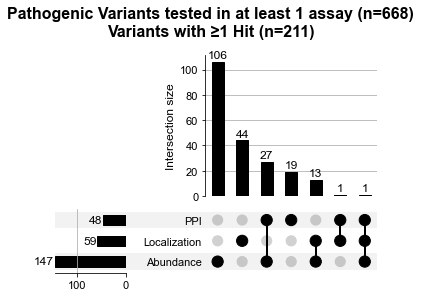

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are se

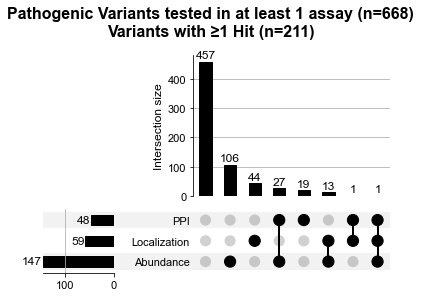

In [ ]:
import polars as pl
import matplotlib.pyplot as plt
from upsetplot import plot as upset_plot
from upsetplot import UpSet

def plot_upset_separate(df_raw):
    # --- Data Prep Function ---
    def prep_data_for_upset(df_input, filter_patho=False):
        valid_df = df_input.filter(
            pl.col("dualipa_score").is_not_null() |
            pl.col("imaging_score").is_not_null() |
            pl.col("ppi_score").is_not_null()
        )
        
        hit_df = valid_df.filter(
            pl.col("dualipa_hit").fill_null(False) |
            pl.col("imaging_hit").fill_null(False) |
            pl.col("ppi_hit").fill_null(False)
        )
        if filter_patho:
            valid_df = valid_df.filter(pl.col("clinvar_clnsig_clean") == "Pathogenic")
            hit_df = hit_df.filter(pl.col("clinvar_clnsig_clean") == "Pathogenic")
            title = f"Pathogenic Variants tested in at least 1 assay (n={len(valid_df)})\nVariants with ≥1 Hit (n={len(hit_df)})"
        else:
            title = f"All Variants (n={len(valid_df)})"

        # Convert to pandas boolean Series
        pdf = valid_df.select([
            pl.col("dualipa_hit").fill_null(False).alias("Abundance"),
            pl.col("imaging_hit").fill_null(False).alias("Localization"),
            pl.col("ppi_hit").fill_null(False).alias("PPI")
        ]).to_pandas()

        # Group by all 3 columns to get counts for UpSet
        upset_data = pdf.groupby(['Abundance', 'Localization', 'PPI']).size()
        return upset_data, title, pdf

    # --- Plot 1: Pathogenic Variants ---
    upset_patho, title_patho, pdf = prep_data_for_upset(df_raw, filter_patho=True)
    
    # Create a dedicated figure for Pathogenic
    fig1 = plt.figure(figsize=(10, 6))
    upset = UpSet(upset_patho, 
                  sort_by='cardinality', 
                  show_counts=True, 
                  totals_plot_elements=3,
                  min_degree=1)  # Hide side bars
    
    # render into the specific figure
    upset.plot(fig=fig1)
    fig1.suptitle(title_patho, fontsize=16, fontweight='bold', y=1.05)
    plt.show()

    # Create a dedicated figure for Pathogenic
    fig1 = plt.figure(figsize=(10, 6))
    upset = UpSet(upset_patho, 
                  sort_by='cardinality', 
                  show_counts=True, 
                  totals_plot_elements=3,
                #   min_degree=1
                  )  # Hide side bars
    
    # render into the specific figure
    upset.plot(fig=fig1)
    fig1.suptitle(title_patho, fontsize=16, fontweight='bold', y=1.05)
    plt.show()
    
    return pdf


# Run it
a = plot_upset_separate(al_dual_img_ppi_assayed_dedup)

In [ ]:
valid_df.filter(pl.col('dualipa_hit') == True)[['dualipa_score', 'imaging_score', 'ppi_score']].to_pandas()

NameError: name 'valid_df' is not defined

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are se

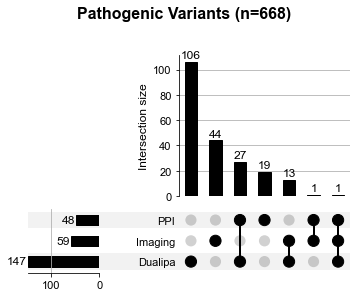

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are se

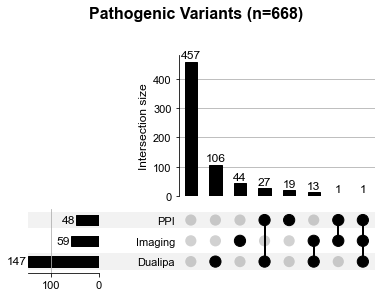

In [ ]:
# at least one assay tested

import polars as pl
import matplotlib.pyplot as plt
from upsetplot import plot as upset_plot
from upsetplot import UpSet

def plot_upset_separate(df_raw):
    # --- Data Prep Function ---
    def prep_data_for_upset(df_input, filter_patho=False):
        valid_df = df_input.filter(
            pl.col("dualipa_score").is_not_null() |
            pl.col("imaging_score").is_not_null() |
            pl.col("ppi_score").is_not_null()
        )
        
        # hit_df = valid_df.filter(
        #     pl.col("dualipa_hit").fill_null(False) |
        #     pl.col("imaging_hit").fill_null(False) |
        #     pl.col("ppi_hit").fill_null(False)
        
        if filter_patho:
            valid_df = valid_df.filter(pl.col("clinvar_clnsig_clean") == "Pathogenic")
            title = f"Pathogenic Variants (n={len(valid_df)})"
        else:
            title = f"All Variants (n={len(valid_df)})"

        # Convert to pandas boolean Series
        pdf = valid_df.select([
            pl.col("dualipa_hit").fill_null(False).alias("Dualipa"),
            pl.col("imaging_hit").fill_null(False).alias("Imaging"),
            pl.col("ppi_hit").fill_null(False).alias("PPI")
        ]).to_pandas()

        # Group by all 3 columns to get counts for UpSet
        upset_data = pdf.groupby(['Dualipa', 'Imaging', 'PPI']).size()
        return upset_data, title

    # --- Plot 1: Pathogenic Variants ---
    upset_patho, title_patho = prep_data_for_upset(df_raw, filter_patho=True)
    
    # Create a dedicated figure for Pathogenic
    fig1 = plt.figure(figsize=(10, 6))
    upset = UpSet(upset_patho, 
                  sort_by='cardinality', 
                  show_counts=True, 
                  totals_plot_elements=3,
                  min_degree=1)  # Hide side bars
    
    # render into the specific figure
    upset.plot(fig=fig1)
    fig1.suptitle(title_patho, fontsize=16, fontweight='bold', y=1.05)
    plt.show()

    # Create a dedicated figure for Pathogenic
    fig1 = plt.figure(figsize=(10, 6))
    upset = UpSet(upset_patho, 
                  sort_by='cardinality', 
                  show_counts=True, 
                  totals_plot_elements=3,
                #   min_degree=1
                  )  # Hide side bars
    
    # render into the specific figure
    upset.plot(fig=fig1)
    fig1.suptitle(title_patho, fontsize=16, fontweight='bold', y=1.05)
    plt.show()


# Run it
plot_upset_separate(al_dual_img_ppi_assayed_dedup)

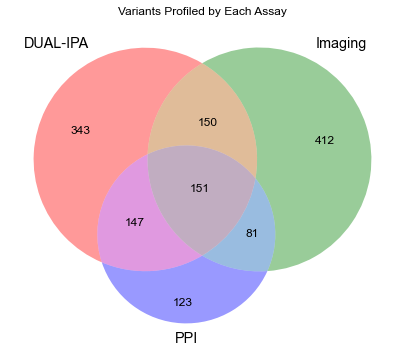

In [ ]:
from matplotlib_venn import venn3
import matplotlib.pyplot as plt

# Get sets of gene_variant IDs for each assay
dualipa_set = set(al_dual_img_ppi_assayed_dedup.filter(pl.col("dualipa_score").is_not_null())["gene_variant"].to_list())
imaging_set = set(al_dual_img_ppi_assayed_dedup.filter(pl.col("imaging_score").is_not_null())["gene_variant"].to_list())
ppi_set = set(al_dual_img_ppi_assayed_dedup.filter(pl.col("ppi_score").is_not_null())["gene_variant"].to_list())

plt.figure(figsize=(7,7))
venn3([dualipa_set, imaging_set, ppi_set], set_labels=('DUAL-IPA', 'Imaging', 'PPI'))
plt.title("Variants Profiled by Each Assay")
plt.show()

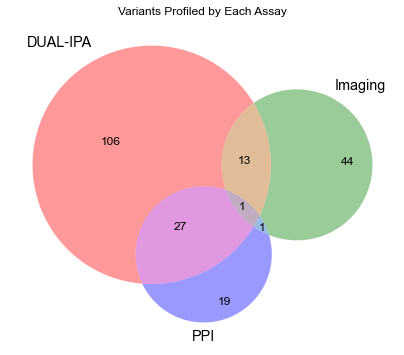

In [ ]:
from matplotlib_venn import venn3
import matplotlib.pyplot as plt

al_dual_patho = al_dual_img_ppi_assayed_dedup.filter(pl.col("clinvar_clnsig_clean") == "Pathogenic")

# Get sets of gene_variant IDs for each assay
dualipa_set = set(al_dual_patho.filter(pl.col("dualipa_hit"))["gene_variant"].to_list())
imaging_set = set(al_dual_patho.filter(pl.col("imaging_hit"))["gene_variant"].to_list())
ppi_set = set(al_dual_patho.filter(pl.col("ppi_hit"))["gene_variant"].to_list())

plt.figure(figsize=(7,7))
venn3([dualipa_set, imaging_set, ppi_set], set_labels=('DUAL-IPA', 'Imaging', 'PPI'))
plt.title("Variants Profiled by Each Assay")
plt.show()

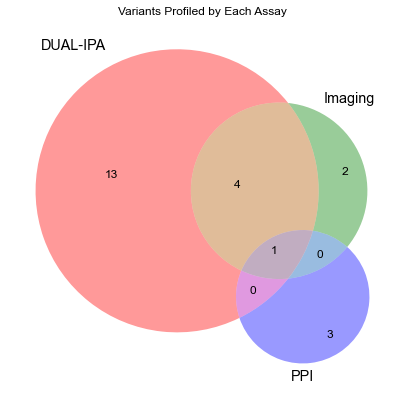

In [ ]:
from matplotlib_venn import venn3
import matplotlib.pyplot as plt

valid_df = al_dual_img_ppi_assayed_dedup.filter(
            pl.col("dualipa_score").is_not_null(),
            pl.col("imaging_score").is_not_null(),
            pl.col("ppi_score").is_not_null()
        ).filter(pl.col("clinvar_clnsig_clean") == "Pathogenic"
        )

# Get sets of gene_variant IDs for each assay
dualipa_set = set(valid_df.filter(pl.col("dualipa_hit"))["gene_variant"].to_list())
imaging_set = set(valid_df.filter(pl.col("imaging_hit"))["gene_variant"].to_list())
ppi_set = set(valid_df.filter(pl.col("ppi_hit"))["gene_variant"].to_list())

plt.figure(figsize=(7,7))
venn3([dualipa_set, imaging_set, ppi_set], set_labels=('DUAL-IPA', 'Imaging', 'PPI'))
plt.title("Variants Profiled by Each Assay")
plt.show()

In [ ]:
a = 1 
b = 2 
c = 3
d = 4

In [ ]:
(a/c)/(b/d)

0.6666666666666666

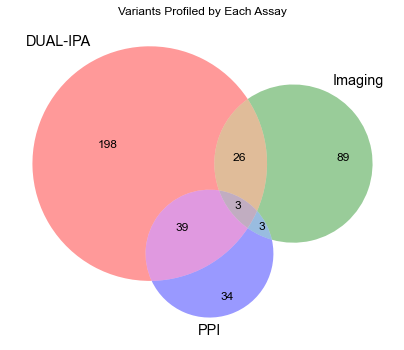

In [ ]:
from matplotlib_venn import venn3
import matplotlib.pyplot as plt

# Get sets of gene_variant IDs for each assay
dualipa_set = set(al_dual_img_ppi_assayed_dedup.filter(pl.col("dualipa_hit"))["gene_variant"].to_list())
imaging_set = set(al_dual_img_ppi_assayed_dedup.filter(pl.col("imaging_hit"))["gene_variant"].to_list())
ppi_set = set(al_dual_img_ppi_assayed_dedup.filter(pl.col("ppi_hit"))["gene_variant"].to_list())

plt.figure(figsize=(7,7))
venn3([dualipa_set, imaging_set, ppi_set], set_labels=('DUAL-IPA', 'Imaging', 'PPI'))
plt.title("Variants Profiled by Each Assay")
plt.show()

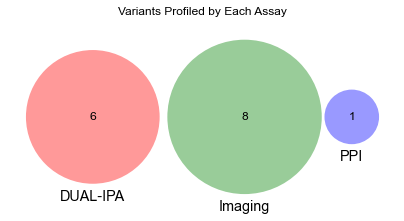

In [ ]:
from matplotlib_venn import venn3
import matplotlib.pyplot as plt

plot_df = al_dual_img_ppi_assayed_dedup.filter(pl.col('clinvar_clnsig_clean') == 'Benign')

# Get sets of gene_variant IDs for each assay
dualipa_set = set(plot_df.filter(pl.col("dualipa_hit"))["gene_variant"].to_list())
imaging_set = set(plot_df.filter(pl.col("imaging_hit"))["gene_variant"].to_list())
ppi_set = set(plot_df.filter(pl.col("ppi_hit"))["gene_variant"].to_list())

plt.figure(figsize=(7,7))
venn3([dualipa_set, imaging_set, ppi_set], set_labels=('DUAL-IPA', 'Imaging', 'PPI'))
plt.title("Variants Profiled by Each Assay")
plt.show()

In [ ]:
len(ppi_set)

79

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are se

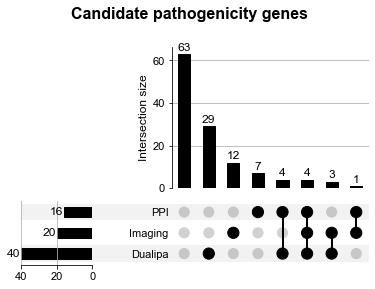

/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
/Users/user_42/.pyenv/versions/3.9.17/lib/python3.9/site-packages/upsetplot/plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are se

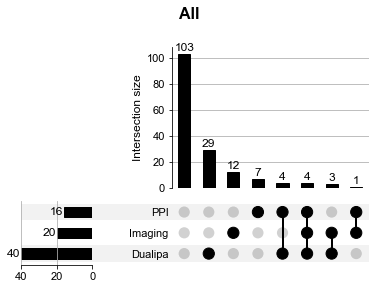

In [ ]:
def plot_upset_gene_level_strict(df_raw):
    def prep_gene_data(df_input, filter_patho=False):
        # 1. Initial cleaning: Keep genes with data for at least one assay
        valid_df = df_input.filter(
            pl.col("dualipa_score").is_not_null() |
            pl.col("imaging_score").is_not_null() |
            pl.col("ppi_score").is_not_null()
        )
        
        # Optional: Restrict universe to genes that actually possess a pathogenic variant
        if filter_patho:
            patho_genes = valid_df.filter(pl.col("clinvar_clnsig_clean") == "Pathogenic") \
                                  .select(pl.col("symbol")).unique()
            valid_df = valid_df.join(patho_genes, on="symbol", how="inner")

        # 2. Collapse to Gene Level with Strict Logic
        # Hit = (At least one Pathogenic Hit) AND (No Benign Hits)
        gene_df = (
            valid_df.group_by("symbol")
            .agg([
                # --- Dualipa ---
                (
                    ((pl.col("clinvar_clnsig_clean") == "Pathogenic") & pl.col("dualipa_hit")).any() & 
                    ~((pl.col("clinvar_clnsig_clean") == "Benign") & pl.col("dualipa_hit")).any()
                ).fill_null(False).alias("Dualipa"),

                # --- Imaging ---
                (
                    ((pl.col("clinvar_clnsig_clean") == "Pathogenic") & pl.col("imaging_hit")).any() & 
                    ~((pl.col("clinvar_clnsig_clean") == "Benign") & pl.col("imaging_hit")).any()
                ).fill_null(False).alias("Imaging"),

                # --- PPI ---
                (
                    ((pl.col("clinvar_clnsig_clean") == "Pathogenic") & pl.col("ppi_hit")).any() & 
                    ~((pl.col("clinvar_clnsig_clean") == "Benign") & pl.col("ppi_hit")).any()
                ).fill_null(False).alias("PPI")
            ])
        )

        title = f"{'Candidate pathogenicity genes' if filter_patho else 'All'}"# Genes (n={len(gene_df)})"

        # 3. Format for UpSet
        upset_data = (
            gene_df.select(["Dualipa", "Imaging", "PPI"])
            .to_pandas()
            .groupby(["Dualipa", "Imaging", "PPI"])
            .size()
        )
        return upset_data, title

    # Plotting Logic
    for is_patho in [True, False]:
        data, title = prep_gene_data(df_raw, filter_patho=is_patho)
        
        fig = plt.figure(figsize=(10, 6))
        upset = UpSet(data, 
                      sort_by='cardinality', 
                      show_counts=True, 
                      totals_plot_elements=3,
                    #   min_degree=1
                      )
        
        upset.plot(fig=fig)
        fig.suptitle(title, fontsize=16, fontweight='bold', y=1.02)
        plt.show()

# Run the strict gene-level analysis
plot_upset_gene_level_strict(al_dual_img_ppi_assayed_dedup)

In [ ]:
stop

NameError: name 'stop' is not defined

### 1.3 Loading DUAL-IPA, Imaging, PPI assayed gene variants

In [ ]:
df_pd = al_dual_img_ppi_assayed_dedup.to_pandas()

In [ ]:
# # Select a subset of columns to export for Leo to add more features to NAM

# df_pd[
# ['symbol',
#  'aa_change',
#  'gene_variant',
#  'spdi',
#  'orf_id',
#  'mut_id',
#  'ensembl_protein_id',
#  'clinvar_clnsig_clean',
#  'AlphaMissense_score','ESM1b_score', 'REVEL_score', 'MutPred_score', 
#  'plddt_f32', 'rsa_f32', 'gnomAD4.1_joint_AF','phyloP100way_vertebrate', 'phastCons100way_vertebrate', 'GERP++_RS', 'PROVEAN_score', 'g2p_Secondary structure (DSSP 9-state)*', 'g2p_Secondary structure (DSSP 3-state)*', 
#  'dualipa_score', 'imaging_score', 'ppi_score']
#       ].to_csv("../3_outputs/0_all_gene_variants_assayed_summary_key_cols_Leo.csv", index=False)

In [ ]:
# plddt_f32:	AlphaFold per-residue confidence score (0-100).	Low pLDDT often indicates intrinsically disordered regions (IDRs). Variants in IDRs behave differently than in structured domains.

# rsa_f32:	Relative Solvent Accessibility.	Distinguishes buried residues (hydrophobic core, critical for stability) from surface residues (interaction interfaces).

# AlphaMissense_score: AlphaMissense is an unsupervised model for predicting the pathogenicity of human missense variants
# 		by incorporating the structural context of an AlphaFold-derived system. The AlphaMissense score ranges from 0 to 1. 
# 		The larger the score, the more likely the variant is pathogenic. Details see https://doi.org/10.1126/science.adg7492.

# ESM1b_score: ESM1b scores are log-likelihood ratio (LLR) scores for predicting the pathogenic effects of coding
# 		variants based on a 650-million-parameter protein language model, ESM1b. The range of ESM1b score in dbNSFP 
# 		is from -24.538 to 6.937. The smaller the score, the more likely the variant is pathogenic. 
# 		Details see doi: https://doi.org/10.1038/s41588-023-01465-0

# REVEL_score: REVEL is an ensemble score based on 13 individual scores for predicting the
# 		pathogenicity of missense variants. Scores range from 0 to 1. The larger the score the more 
# 		likely the SNP has a damaging effect. "REVEL scores are freely available for non-commercial use.  
# 		For other uses, please contact Weiva Sieh" (weiva.sieh@mssm.edu)

# MutPred2_score: General MutPred2 score. Scores range from 0 to 1. The larger the score the more
# 		likely the SNP has a damaging effect.

# gnomAD4.1_joint_nhomalt: Count of individuals with homozygous alternative allele in the whole gnomAD joint (genome+exome) samples v4.1

# phyloP100way_vertebrate: phyloP (phylogenetic p-values) conservation score based on the
# 		multiple alignments of 100 vertebrate genomes (including human). The larger the score, 
# 		the more conserved the site. Scores range from -20.0 to 10.003 in dbNSFP.

# phastCons100way_vertebrate: phastCons conservation score based on the multiple alignments
# 		of 100 vertebrate genomes (including human). The larger the score, the more conserved 
# 		the site. Scores range from 0 to 1. 

# GERP++_RS: GERP++ RS score, the larger the score, the more conserved the site. Scores range from
# 		-12.3 to 6.17.
  
# DSSP provides an elaborate description of the secondary structure elements in a protein structure, including backbone hydrogen bonding and the topology of β-sheets. The most popular feature is the per-residue assignment of secondary structure with a single character code:

# 		H = α-helix
# 		B = residue in isolated β-bridge
# 		E = extended strand, participates in β ladder
# 		G = 310-helix
# 		I = π-helix
# 		P = κ-helix (poly-proline II helix)
# 		T = hydrogen-bonded turn
# 		S = bend
# 		C = Coil

# g2p_Secondary structure (DSSP 9-state)* lists all 9 possible state while g2p_Secondary structure (DSSP 3-state)* only lists 3, H (Helix), B (Beta sheet), C (Coil)

# PROVEAN_score: PROVEAN score (PROVEANori). Scores range from -14 to 14. The smaller the score
# 		the more likely the SNP has damaging effect. 


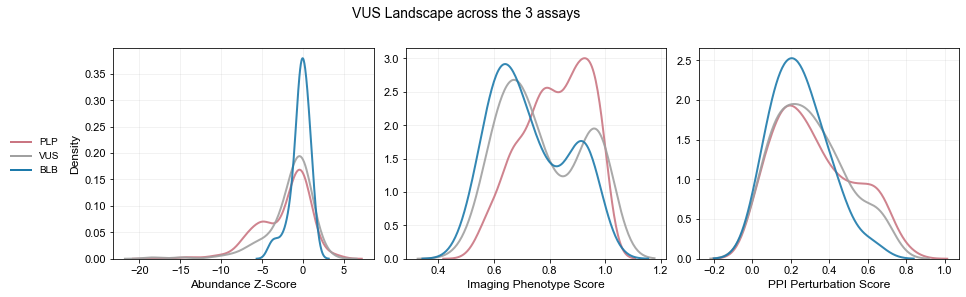

In [ ]:
# Plot VUS density vs Benign and Pathogenic for the 3 assays
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# Define the assays and their labels
assays = ["dualipa_score", "imaging_score", "ppi_score"]
assay_labels = ["Abundance Z-Score", "Imaging Phenotype Score", "PPI Perturbation Score"]

# Categories to compare
categories = ["Pathogenic", "VUS", "Benign"]
colors = {
    "Pathogenic": palette_dict["clinvar_clnsig_clean"]["Pathogenic"],
    "Benign": palette_dict["clinvar_clnsig_clean"]["Benign"],
    "VUS": palette_dict["clinvar_clnsig_clean"]["VUS"]
}


handles = []
labels = []

for i, (assay, label) in enumerate(zip(assays, assay_labels)):
    ax = axes[i]
    
    for cat in categories:
        data = al_dual_img_ppi_assayed_dedup.filter(
            pl.col("clinvar_clnsig_clean") == cat,
            pl.col(assay).is_not_null()
        )[assay].to_numpy()
        
        if len(data) > 0:
            line = sns.kdeplot(
                data=data,
                ax=ax,
                color=colors[cat],
                label=f"{cat} (n={len(data)})",
                alpha=0.9,
                linewidth=2
            )
            # Only collect handles from first subplot
            if i == 0:
                handles.append(plt.Line2D([0], [0], color=colors[cat], linewidth=2))
                # Map category names to desired legend labels
                label_map = {"Pathogenic": "PLP", "Benign": "BLB", "VUS": "VUS"}
                labels.append(label_map[cat])
    
    ax.set_xlabel(label)
    ax.set_ylabel("Density" if i == 0 else "")
    ax.grid(alpha=0.2)
    ax.legend().remove()  # Remove individual legends

# Add shared legend to the left of the first subplot
fig.legend(handles, labels, loc='center left', bbox_to_anchor=(0.04, 0.5), 
           fontsize=10, frameon=False)

plt.suptitle("VUS Landscape across the 3 assays", fontsize=14, y=1.02)
plt.tight_layout()
plt.subplots_adjust(left=0.15)  # Make room for legend
# plt.savefig("../4_manuscript_figures/VUS_density_vs_pathogenic_benign.svg", 
#             format='svg', dpi=400, bbox_inches='tight', transparent=True)
plt.show()

In [ ]:
al_dual_img_ppi_assayed_dedup = pl.read_csv(
    "../3_outputs/0_all_gene_variants_assayed_summary.tsv",
    separator="\t", infer_schema_length=100000
)

print(
    al_dual_img_ppi_assayed_dedup.group_by("clinvar_clnsig_clean_pp_strict").agg(
        pl.len().alias("n_variants"),
    ).sort("n_variants", descending=True)
)

print(
    al_dual_img_ppi_assayed_dedup.with_columns(
    pl.sum_horizontal(
        [
            pl.col("ppi_score").is_not_null(),
            pl.col("dualipa_score").is_not_null(),
            pl.col("imaging_score").is_not_null(),
        ]
    ).alias("assay_tested")
).select(
    ["gene_variant","assay_tested"]
).group_by(
    "assay_tested"
).agg(pl.len()).sort("assay_tested")
)

shape: (7, 2)
┌────────────────────────────────┬────────────┐
│ clinvar_clnsig_clean_pp_strict ┆ n_variants │
│ ---                            ┆ ---        │
│ str                            ┆ u32        │
╞════════════════════════════════╪════════════╡
│ Pathogenic                     ┆ 415        │
│ Likely pathogenic              ┆ 264        │
│ Conflicting                    ┆ 239        │
│ VUS                            ┆ 213        │
│ Others                         ┆ 134        │
│ Likely benign                  ┆ 96         │
│ Benign                         ┆ 66         │
└────────────────────────────────┴────────────┘
shape: (3, 2)
┌──────────────┬─────┐
│ assay_tested ┆ len │
│ ---          ┆ --- │
│ u32          ┆ u32 │
╞══════════════╪═════╡
│ 1            ┆ 889 │
│ 2            ┆ 387 │
│ 3            ┆ 151 │
└──────────────┴─────┘


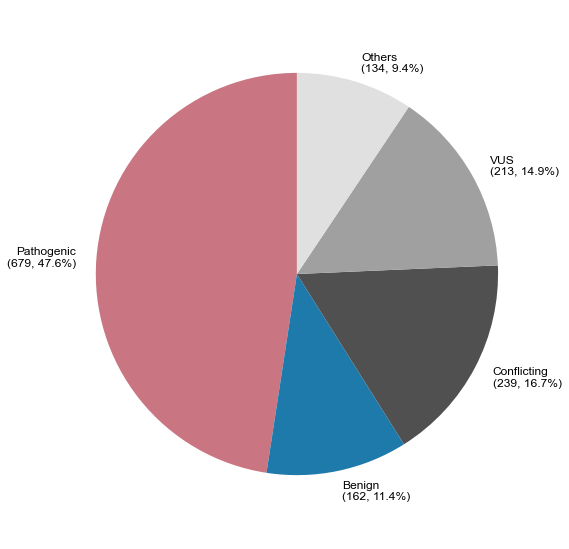

In [ ]:
# Create pie chart for ClinVar annotation categories
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
# Get the category counts from the merged data
summary_clin_var_counts = al_dual_img_ppi_assayed_dedup.group_by("clinvar_clnsig_clean").agg(pl.len()).to_pandas()
summary_clin_var_counts['clinvar_clnsig_clean'] = pd.Categorical(
    summary_clin_var_counts['clinvar_clnsig_clean'], 
    categories=[c for c in clinvar_order_dict["original"] if "Likely" not in c], 
    ordered=True
)

# Convert to pandas for easier plotting
pie_data = summary_clin_var_counts.sort_values('clinvar_clnsig_clean')

# Calculate percentages
total_count = pie_data["len"].sum()
pie_data["percentage"] = (pie_data["len"] / total_count * 100).round(1)

# Create labels with counts and percentages
labels = [f"{cat}\n({count}, {pct}%)" for cat, count, pct in zip(pie_data["clinvar_clnsig_clean"], 
                                                                 pie_data["len"], 
                                                                 pie_data["percentage"])
]
colors = [palette_dict["clinvar_clnsig_clean"][cat] for cat in pie_data["clinvar_clnsig_clean"]]
# Create pie chart
wedges, texts, autotexts = ax.pie(pie_data["len"], 
                                  labels=labels, 
                                  colors=colors,
                                  autopct="",  # We're including percentages in labels
                                  startangle=90,
                                  counterclock=True,
                                  textprops={'fontsize': 12})

# ax.set_title("Distribution of ClinVar Annotation Categories", fontsize=14, fontweight='bold', pad=20)
# Equal aspect ratio ensures that pie is drawn as a circle
ax.axis('equal')

# # Add a legend
# ax.legend(wedges, [f"{cat} (n={count})" for cat, count in zip(pie_data["clinvar_clnsig_clean"], pie_data["len"])],
#           title="Categories",
#           loc="center left",
#           bbox_to_anchor=(1, 0, 0.5, 1))

plt.tight_layout()
plt.show()

# Print summary statistics

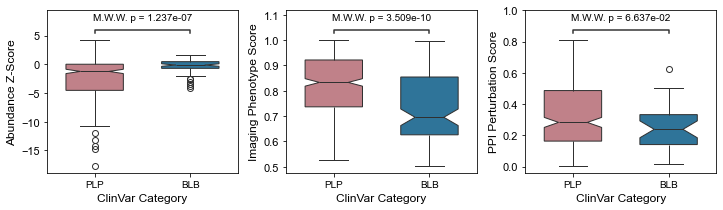

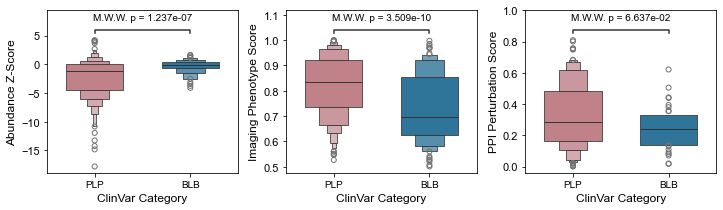

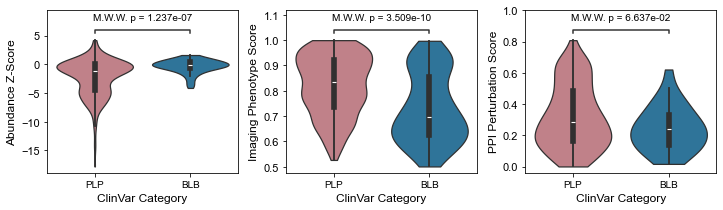

In [ ]:
def plot_assay_scores(df, type="box"):
    fig, axes = plt.subplots(1, 3, figsize=(12, 3))
    for i, assay in enumerate(["dualipa_score", "imaging_score", "ppi_score"]):
        if type == "box":
            sns.boxplot(
                data=df.filter(
                    pl.col("clinvar_clnsig_clean").is_in(["Pathogenic", "Benign"])
                ).to_pandas(),
                x="clinvar_clnsig_clean",
                y=assay,
                hue="clinvar_clnsig_clean",
                palette=palette_dict["clinvar_clnsig_clean"],
                width=0.6,
                notch=True,
                order=[c for c in clinvar_order_dict["original"] if "Likely" not in c],
                ax=axes[i],
                legend=False
            )
        if type == "boxen":
            sns.boxenplot(
                data=df.filter(
                    pl.col("clinvar_clnsig_clean").is_in(["Pathogenic", "Benign"])
                ).to_pandas(),
                x="clinvar_clnsig_clean",
                y=assay,
                hue="clinvar_clnsig_clean",
                palette=palette_dict["clinvar_clnsig_clean"],
                width=0.6,
                order=[c for c in clinvar_order_dict["original"] if "Likely" not in c],
                ax=axes[i],
                legend=False
            )
        if type == "violin":
            sns.violinplot(
                data=df.filter(
                    pl.col("clinvar_clnsig_clean").is_in(["Pathogenic", "Benign"])
                ).to_pandas(),
                x="clinvar_clnsig_clean",
                y=assay,
                hue="clinvar_clnsig_clean",
                palette=palette_dict["clinvar_clnsig_clean"],
                cut=0,
                order=[c for c in clinvar_order_dict["original"] if "Likely" not in c],
                ax=axes[i],
                legend=False
            )

        axes[i].set_xlim(-0.5, 1.5)
        # Annotator expects the pairs and corresponding x, hue information
        annotator = Annotator(axes[i], 
                            [("Pathogenic", "Benign")], 
                            data=df.filter(
                                        pl.col("clinvar_clnsig_clean").is_in(["Pathogenic", "Benign"]),
                                        pl.col(assay).is_not_null()
                                    ).to_pandas(), 
                            x="clinvar_clnsig_clean", 
                            y=assay,
                            hue="clinvar_clnsig_clean",
                            order=[c for c in clinvar_order_dict["original"] if "Path" in c or "Benign" in c],
                            verbose=False
        )
        annotator.configure(test="Mann-Whitney",#test='Mann-Whitney-gt', 
                            # test_short_name='M.W.W.', 
                            #comparisons_correction="Bonferroni", 
                            text_format='full', loc='inside', text_offset=8,
                            # test_kw={'alternative': 'greater'},  # or 'less'
                            verbose=False)
        annotator.apply_test()
        annotator.annotate(line_offset_to_group=0.05, line_offset=0.15)#.apply_and_annotate() | .apply_test()
        # axes[i].grid(alpha=.2, axis="y")
        axes[i].xaxis.set_major_locator(FixedLocator(range(2)))
        axes[i].set_xticklabels(["PLP","BLB"], fontsize=10)
        axes[i].set_xlabel("ClinVar Category")

    axes[0].set_ylabel("Abundance Z-Score")
    axes[1].set_ylabel("Imaging Phenotype Score")
    axes[2].set_ylabel("PPI Perturbation Score")
    plt.subplots_adjust(wspace=0.25)
    fig.savefig(
        f"../4_manuscript_figures/assay_phenotyping_score_{type}_dist_clinvar.svg",
        format='svg',
        dpi=400,
        bbox_inches='tight',
        transparent=True
    )
    plt.show()

plot_assay_scores(al_dual_img_ppi_assayed_dedup, "box")
plot_assay_scores(al_dual_img_ppi_assayed_dedup, "boxen")
plot_assay_scores(al_dual_img_ppi_assayed_dedup, "violin")

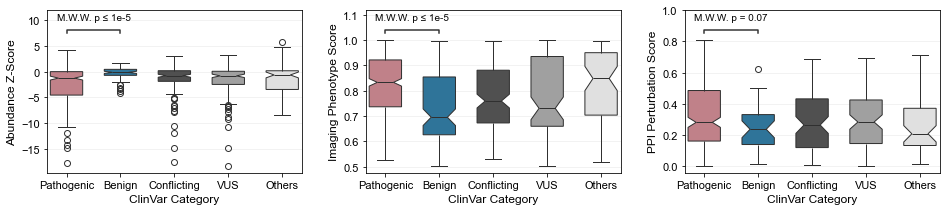

In [ ]:
def plot_assay_scores(df, type="box"):
    fig, axes = plt.subplots(1, 3, figsize=(16, 3))
    for i, assay in enumerate(["dualipa_score", "imaging_score", "ppi_score"]):
        if type == "box":
            sns.boxplot(
                data=df.to_pandas(),
                x="clinvar_clnsig_clean",
                y=assay,
                hue="clinvar_clnsig_clean",
                palette=palette_dict["clinvar_clnsig_clean"],
                width=0.6,
                notch=True,
                order=[c for c in clinvar_order_dict["original"] if "Likely" not in c],
                ax=axes[i],
                legend=False
            )
        if type == "boxen":
            sns.boxenplot(
                data=df.to_pandas(),
                x="clinvar_clnsig_clean",
                y=assay,
                hue="clinvar_clnsig_clean",
                palette=palette_dict["clinvar_clnsig_clean"],
                width=0.6,
                order=[c for c in clinvar_order_dict["bio_descending"] if "Likely" not in c],
                ax=axes[i],
                legend=False
            )
        if type == "violin":
            sns.violinplot(
                data=df.to_pandas(),
                x="clinvar_clnsig_clean",
                y=assay,
                hue="clinvar_clnsig_clean",
                palette=palette_dict["clinvar_clnsig_clean"],
                cut=0,
                order=[c for c in clinvar_order_dict["bio_descending"] if "Likely" not in c],
                ax=axes[i],
                legend=False
            )

        # axes[i].set_xlim(-0.5, 1.5)
        # # Annotator expects the pairs and corresponding x, hue information
        annotator = Annotator(axes[i], 
                              [("Pathogenic", "Benign")], 
                              data=df.filter(
                                        # pl.col("clinvar_clnsig_clean").is_in(["Pathogenic", "Benign"]),
                                        pl.col(assay).is_not_null()
                                    ).to_pandas(), 
                            x="clinvar_clnsig_clean", 
                            y=assay,
                            hue="clinvar_clnsig_clean",
                            order=[c for c in clinvar_order_dict["bio_descending"] if "Path" in c or "Benign" in c],
                            verbose=False
        )
        annotator.configure(test="Mann-Whitney",#test='Mann-Whitney-gt', 
                            test_short_name='M.W.W.\n', 
                            #comparisons_correction="Bonferroni", 
                            text_format='simple', 
                            loc='inside', text_offset=8,
                            # test_kw={'alternative': 'greater'},  # or 'less'
                            verbose=False)
        annotator.apply_test()
        annotator.annotate(line_offset_to_group=0.05, line_offset=0.15)#.apply_and_annotate() | .apply_test()
        axes[i].grid(alpha=.2, axis="y")
        # axes[i].xaxis.set_major_locator(FixedLocator(range(2)))
        # axes[i].set_xticklabels(["PLP","BLB"], fontsize=10)
        axes[i].set_xlabel("ClinVar Category")

    axes[0].set_ylabel("Abundance Z-Score")
    axes[1].set_ylabel("Imaging Phenotype Score")
    axes[2].set_ylabel("PPI Perturbation Score")
    plt.subplots_adjust(wspace=0.25)
    # fig.savefig(
    #     f"../4_manuscript_figures/assay_phenotyping_score_{type}_dist_clinvar.svg",
    #     format='svg',
    #     dpi=400,
    #     bbox_inches='tight',
    #     transparent=True
    # )
    plt.show()

plot_assay_scores(al_dual_img_ppi_assayed_dedup, "box")

In [ ]:
al_dual_img_ppi_assayed_dedup.unique("pLDDT_Category")["pLDDT_Category"]

pLDDT_Category
str
""">90"""
"""NaN"""
"""70-90"""
"""$\leqslant$50"""
"""50-70"""


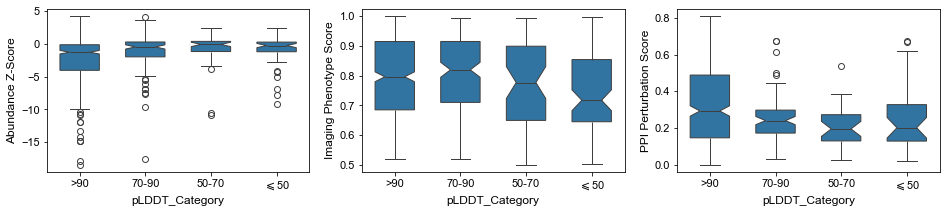

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3))
for i, assay in enumerate(["dualipa_score", "imaging_score", "ppi_score"]):
    sns.boxplot(
        data=al_dual_img_ppi_assayed_dedup.filter(
            pl.col("pLDDT_Category")!="NaN"
        ).to_pandas(),
        x="pLDDT_Category",
        y=assay,
        order=[">90","70-90","50-70","$\leqslant$50"],
        # hue="clinvar_clnsig_clean",
        width=0.6,
        notch=True,
        ax=axes[i],
        legend=False
    )
axes[0].set_ylabel("Abundance Z-Score")
axes[1].set_ylabel("Imaging Phenotype Score")
axes[2].set_ylabel("PPI Perturbation Score")
plt.show()

In [ ]:
for assay in ["dualipa_hit", "imaging_hit", "ppi_hit"]:
    print(assay)
    contingency_table = al_dual_img_ppi_assayed_dedup.filter(
        pl.col(assay).is_not_null(),
        pl.col("clinvar_clnsig_clean").is_in(["Pathogenic", "Benign"]),
    ).group_by(
        [assay, 'clinvar_clnsig_clean']
    ).agg(
        pl.len()
    ).pivot(
        index=assay,
        on='clinvar_clnsig_clean',
        values="len"
    ).sort(
        assay, descending=True
    )
    print(
        contingency_table.select(
            (pl.col("Pathogenic").first() / pl.col("Pathogenic").sum()).alias("Pathogenic_hit_rate"),
            (pl.col("Benign").first() / pl.col("Benign").sum()).alias("Benign_hit_rate")
        )
    )
    table = contingency_table.select(["Pathogenic", "Benign"]).to_numpy()  # Flip so true is first row
    odds_ratio, p_value = fisher_exact(table, alternative='two-sided')
    print(odds_ratio, p_value)

dualipa_hit
shape: (1, 2)
┌─────────────────────┬─────────────────┐
│ Pathogenic_hit_rate ┆ Benign_hit_rate │
│ ---                 ┆ ---             │
│ f64                 ┆ f64             │
╞═════════════════════╪═════════════════╡
│ 0.4                 ┆ 0.070423        │
└─────────────────────┴─────────────────┘
8.8 7.802825514568112e-09
imaging_hit
shape: (1, 2)
┌─────────────────────┬─────────────────┐
│ Pathogenic_hit_rate ┆ Benign_hit_rate │
│ ---                 ┆ ---             │
│ f64                 ┆ f64             │
╞═════════════════════╪═════════════════╡
│ 0.166667            ┆ 0.066667        │
└─────────────────────┴─────────────────┘
2.8 0.006621739987160036
ppi_hit
shape: (1, 2)
┌─────────────────────┬─────────────────┐
│ Pathogenic_hit_rate ┆ Benign_hit_rate │
│ ---                 ┆ ---             │
│ f64                 ┆ f64             │
╞═════════════════════╪═════════════════╡
│ 0.188               ┆ 0.032258        │
└─────────────────────┴────────────

In [ ]:
al_dual_img_ppi_assayed_dedup.unique("symbol")

symbol,aa_change,gene_variant,spdi,nt_change,chr_num,nuc_loc,ref_allele,alt_allele,Chrom,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,ensembl_protein_id,collection,entry_plate_orig,entry_well_orig,entry_plate_conso,entry_well_conso,entry_seq_pool,db_plate,db_well,n2h_plate,n2h_well,dualip_plate,dualip_well,mislocalization_plate,mislocalization_well,entry_sequenced,entry_sequence_confirmation_class,db_sequenced,db_sequence_confirmation_class,n2h_sequenced,n2h_sequence_confirmation_class,n2h_ref_sequence_confirmation_class,…,g2p_Substrate genes,g2p_Topological domain (UniProt),g2p_Transit peptide (UniProt),g2p_Transmembrane (UniProt),g2p_Ubiquitination,g2p_Zinc finger (UniProt),plddt_f32,rsa_f32,pLDDT_Category,RSA_Category,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names,splicing_variant,dualipa_score,dualipa_abun_change,dualipa_abun_chg_dir,dualipa_hit,ppi_num_edges,ppi_score,ppi_hit,img_U2OS_cc_t_stat,img_U2OS_cc_t_pval,img_U2OS_cc_t_adj_pval,img_U2OS_prot_abun_t_stat,img_U2OS_prot_abun_t_pval,img_U2OS_prot_abun_t_adj_pval,img_Metadata_Bio_Batch,imaging_score,img_misloc_score,img_pheno_hit,img_misloc_hit,img_pheno_hit_strict,imaging_hit
str,str,str,str,str,i64,i64,str,str,str,str,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,f64,f64,f64,f64,f64,…,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,i64,str,bool,f64,str,str,bool,i64,f64,bool,f64,f64,f64,f64,f64,f64,str,f64,f64,bool,bool,bool,bool
"""IL2RG""","""Arg285Gln""","""IL2RG_Arg285Gln""","""NC_000023.11:71108598:C:T""","""854G>A""",23,71108599,"""C""","""T""","""X""","""ENSG00000147168""",7651,13909,"""CCSBVarC001218""","""ALE00001218""","""ENSP00000363318.3""","""RC4""","""RC4_Mut_GDEh1018""","""H08""","""GDEhDisVCh_40084""","""B09""","""2""","""RC4_Mut_GDDh1018""","""H08""","""NULL""","""NULL""","""NULL""","""NULL""","""VUSmut_GDEh13""","""G02""",1.0,1.0,1.0,7.0,0.0,null,null,…,null,"""Cytoplasmic""",null,null,null,null,74.55,92.741936,"""70-90""","""$\geqslant$90""","""300400""","""x-linked recessive""","""OMIM""","""Rare genetic immune disease""",1,"""SEVERE COMBINED IMMUNODEFICIEN…",true,null,null,null,null,null,null,null,0.269273,0.795484,0.838507,2.29988,0.055001,0.077102,"""2024_01_Batch_7-8""",0.634495,0.589664,false,false,false,false
"""PNKP""","""Glu326Lys""","""PNKP_Glu326Lys""","""NC_000019.10:49862423:C:T""","""976G>A""",19,49862424,"""C""","""T""","""19""","""ENSG00000039650""",9905,216952,"""CCSBVarC004010""","""ALE00004010""","""ENSP00000323511.2""","""CEGS2""","""CegsMutGDEh1033""","""A11""","""GDEhDisVCh_40018""","""E01""","""2""","""CegsMutGDDh1033""","""A11""","""VUSN2Hmut_GDN2h_06""","""C06""","""VUSMutpDEST2_08""","""E09""","""VUSmut_GDEh06""","""C06""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,…,null,null,null,null,null,null,98.1,16.494844,""">90""","""10-90""","""613402;613722""","""autosomal recessive""","""OMIM""","""Rare genetic eye disease; Rare…",2,"""MICROCEPHALY, SEIZURES, AND DE…",false,null,null,null,null,12,0.358988,false,-4.147863,0.004307,0.014305,-5.963346,0.000562,0.001516,"""2025_03_Batch_15-16""",0.823722,0.815897,false,false,false,false
"""ASNS""","""Ala6Glu""","""ASNS_Ala6Glu""","""NC_000007.14:97869139:G:T""","""17C>A""",7,97869140,"""G""","""T""","""7""","""ENSG00000070669""",6018,215806,"""CCSBVarC003708""","""ALE00003708""","""ENSP00000377845.3""","""CEGS2""","""CegsMutGDEh1033""","""D07""","""GDEhDisVCh_40034""","""E12""","""2""","""CegsMutGDDh1033""","""D07""","""VUSN2Hmut_GDN2h_06""","""G04""","""VUSMutpDEST2_05""","""F08""","""VUSmut_GDEh06""","""G04""",1.0,1.0,1.0,1.0,1.0,1.0,1.0,…,null,null,null,null,null,null,98.19,0.0,""">90""","""<10""","""615574""","""autosomal recessive""","""OMIM""","""Rare genetic neurological diso…",2,"""ASPARAGINE SYNTHETASE DEFICIEN…",false,-5.118433,"""Y""","""Decrease""",true,1,0.573239,true,null,null,null,null,null,null,null,null,null,null,null,null,null
"""KCNJ2""","""Ala115Val""","""KCNJ2_

## 2. Plot Gene-level Summary per Assay

In [ ]:
def explained_gene_per_assay(assay_df, show_plot=False, benign_thres=1e-3, pathogenic_thres=1e-3, palette_name="clinvar_clnsig_clean"):
    """
    Analyze gene-level performance in functional assays with classification.

    Returns all genes with hit percentages and classification based on thresholds.
    """
    df = plot_gene_level_summary(
        assay_df,
        assay="assay_hit",
        cat="clinvar_clnsig_clean",
        plot=show_plot,
        palette=palette_dict[palette_name]
    ).to_pandas()

    # Create pivot table to get hit percentages by gene and clinvar category
    # display(df)
    gene_summary = df.pivot(index='symbol', columns='clinvar_clnsig_clean', values='hit_perc').fillna(0)
    
    # Get benign and pathogenic columns (if they exist)
    benign_col = 'Benign' if 'Benign' in gene_summary.columns else None
    pathogenic_col = 'Pathogenic' if 'Pathogenic' in gene_summary.columns else None

    # Add classification column based on criteria
    def classify_gene(row):
        benign_rate = row[benign_col] if benign_col else float('inf')
        pathogenic_rate = row[pathogenic_col] if pathogenic_col else 0

        # Meets both criteria (low false positive, high true positive)
        if benign_col and pathogenic_col:
            if benign_rate < benign_thres and pathogenic_rate > pathogenic_thres:
                return "High_Discriminatory"
            elif benign_rate >= benign_thres and pathogenic_rate <= pathogenic_thres:
                return "Low_Discriminatory"
            elif benign_rate < benign_thres and pathogenic_rate <= pathogenic_thres:
                return "Low_Sensitivity"
            elif benign_rate >= benign_thres and pathogenic_rate > pathogenic_thres:
                return "High_False_Positive"
            else:
                return "Unclear"
        elif benign_col:
            return "Low_FP" if benign_rate < benign_thres else "High_FP"
        elif pathogenic_col:
            return "High_Sensitivity" if pathogenic_rate > pathogenic_thres else "Low_Sensitivity"
        else:
            return "No_Classification"

    # Add simple pass/fail column
    def passes_threshold(row):
        benign_rate = row[benign_col] if benign_col else float('inf')
        pathogenic_rate = row[pathogenic_col] if pathogenic_col else 0

        if benign_col and pathogenic_col:
            return (benign_rate < benign_thres) and (pathogenic_rate > pathogenic_thres)
        elif benign_col:
            return benign_rate < benign_thres
        elif pathogenic_col:
            return pathogenic_rate > pathogenic_thres
        else:
            return False

    # Apply classification and pass/fail
    gene_summary['Classification'] = gene_summary.apply(classify_gene, axis=1)
    gene_summary['Passes_Threshold'] = gene_summary.apply(passes_threshold, axis=1)

    # Add summary statistics
    gene_summary_with_stats = gene_summary.copy()

    # Count variants by adding total counts from original df
    variant_counts = df.groupby('symbol').agg({
        'total_counts': 'first',
        'total_counts_all': 'first',
        'hit_counts': 'first'
    })
    gene_summary_with_stats = gene_summary_with_stats.join(variant_counts, how='left')

    # --- Fisher's exact test comparing Pathogenic vs Benign hits per gene ---
    # Prepare aggregated counts from df (symbol x clinvar)
    # df has columns: symbol, clinvar_clnsig_clean, total_counts, hit_counts
    fisher_df = None
    agg = df.groupby(['symbol', 'clinvar_clnsig_clean']).agg({
        'hit_counts': 'sum',
        'total_counts': 'sum'
    }).reset_index()

    # iterate genes in gene_summary_with_stats
    records = []
    for gene in gene_summary_with_stats.index:
        sub = agg[agg['symbol'] == gene]
        # pathogenic
        p_row = sub[sub['clinvar_clnsig_clean'] == 'Pathogenic']
        ph = int(p_row['hit_counts'].sum()) if not p_row.empty else 0
        pt = int(p_row['total_counts'].sum()) if not p_row.empty else 0
        # benign
        b_row = sub[sub['clinvar_clnsig_clean'] == 'Benign']
        bh = int(b_row['hit_counts'].sum()) if not b_row.empty else 0
        bt = int(b_row['total_counts'].sum()) if not b_row.empty else 0

        # non-hit counts
        p_non = max(0, pt - ph)
        b_non = max(0, bt - bh)

        odds, pval = np.nan, np.nan
        # require at least one observation in the 2x2 table
        if (pt + bt) > 0:
            try:
                odds, pval = fisher_exact([[ph, p_non], [bh, b_non]], alternative='two-sided')
            except Exception:
                odds, pval = np.nan, np.nan

        records.append({
            'symbol': gene,
            'fisher_oddsratio': odds,
            'fisher_pval': pval,
            'pathogenic_hit': ph,
            'pathogenic_total': pt,
            'pathogenic_nonhit': p_non,
            'benign_hit': bh,
            'benign_total': bt,
            'benign_nonhit': b_non
        })

    fisher_df = pd.DataFrame.from_records(records).set_index('symbol')
    gene_summary_with_stats = gene_summary_with_stats.join(fisher_df, how='left')

    # Print summary statistics
    classification_counts = gene_summary['Classification'].value_counts()
    passes_count = gene_summary['Passes_Threshold'].sum()
    # print(f"Gene Classification Summary (n={len(gene_summary)} genes):")
    # for classification, count in classification_counts.items():
    #     print(f"  {classification}: {count} genes")

    print(f"\nGenes passing threshold: {passes_count}/{len(gene_summary)} ({passes_count/len(gene_summary)*100:.1f}%)")

    if benign_col and pathogenic_col:
        high_disc_genes = gene_summary[gene_summary['Passes_Threshold'] == True]
        print(f"Genes passing criteria (benign < {benign_thres}% AND pathogenic > {pathogenic_thres}%): {len(high_disc_genes)}")
        # if len(high_disc_genes) > 0:
        #     print("Genes:", sorted(high_disc_genes.index.tolist()))

    return gene_summary_with_stats

In [ ]:
genes_with_patho_variants = al_dual_img_ppi_assayed_dedup.filter(
    pl.col("clinvar_clnsig_clean").is_in(["Pathogenic"])
).unique("symbol")["symbol"].to_list()

dual_ipa_gene = explained_gene_per_assay(al_dual_img_ppi_assayed_dedup.filter(
    pl.col("dualipa_abun_change").is_not_null(),
    pl.col("symbol").is_in(genes_with_patho_variants)
).with_columns(
    pl.when(pl.col("dualipa_abun_change")=="Y")
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("assay_hit")
))

imaging_gene = explained_gene_per_assay(al_dual_img_ppi_assayed_dedup.filter(
    pl.col("img_pheno_hit").is_not_null(),
    pl.col("symbol").is_in(genes_with_patho_variants)
).with_columns(
    pl.when(pl.col("img_pheno_hit"))
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("assay_hit")
))

ppi_gene = explained_gene_per_assay(al_dual_img_ppi_assayed_dedup.filter(
    pl.col("ppi_hit").is_not_null(),
    pl.col("symbol").is_in(genes_with_patho_variants)
).with_columns(
    pl.when(pl.col("ppi_hit"))
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("assay_hit")
))


Genes passing threshold: 44/71 (62.0%)
Genes passing criteria (benign < 0.001% AND pathogenic > 0.001%): 44

Genes passing threshold: 22/88 (25.0%)
Genes passing criteria (benign < 0.001% AND pathogenic > 0.001%): 22

Genes passing threshold: 15/66 (22.7%)
Genes passing criteria (benign < 0.001% AND pathogenic > 0.001%): 15


### Three assays tested

In [ ]:
# Merge imaging_gene and dual_ipa_gene based on union of their indices
merged_genes_any_path = imaging_gene.join(dual_ipa_gene, how='outer', lsuffix='_imaging', rsuffix='_dualipa')
merged_genes_any_path = merged_genes_any_path.join(ppi_gene, how='outer', rsuffix='_ppi')

# Display the merged result
print(f"Imaging genes: {len(imaging_gene)}")
print(f"Dual-IPA genes: {len(dual_ipa_gene)}")
print(f"PPI genes: {len(ppi_gene)}")
print(f"Merged genes (union): {len(merged_genes_any_path)}")
print(f"Genes in ALL three assays: {len(set(imaging_gene.index).intersection(set(dual_ipa_gene.index)).intersection(set(ppi_gene.index)))}")

merged_genes_any_path[["Passes_Threshold_imaging", "Passes_Threshold_dualipa", "Passes_Threshold"]]
merged_genes_any_path["true_count"] = merged_genes_any_path[["Passes_Threshold_imaging", "Passes_Threshold_dualipa", "Passes_Threshold"]].sum(axis=1)
merged_genes_any_path["non_null_count"] = merged_genes_any_path[["Passes_Threshold_imaging", "Passes_Threshold_dualipa", "Passes_Threshold"]].notna().sum(axis=1)
merged_genes_any_path = merged_genes_any_path.sort_values(by=["non_null_count","true_count"], ascending=[False,False])

overlapped_genes_any_path = list(set(imaging_gene.index).intersection(set(dual_ipa_gene.index)).intersection(set(ppi_gene.index)))
# Prepare data for heatmap - handle NaN values properly
heatmap_data = merged_genes_any_path.loc[overlapped_genes_any_path,["Passes_Threshold_imaging", "Passes_Threshold_dualipa", "Passes_Threshold"]].rename(
    {
        "Passes_Threshold_imaging": "Imaging",
        "Passes_Threshold_dualipa": "DUAL-IPA",
        "Passes_Threshold": "PPI"
    }, axis=1
).copy()

overlapped_genes = list(set(imaging_gene.index).intersection(set(dual_ipa_gene.index)).intersection(set(ppi_gene.index)))

# Prepare data for heatmap - handle NaN values properly
heatmap_data = merged_genes_any_path.loc[overlapped_genes,["Passes_Threshold_dualipa", "Passes_Threshold_imaging", "Passes_Threshold"]].rename(
    {
        "Passes_Threshold_dualipa": "Abundance",
        "Passes_Threshold_imaging": "Imaging",
        "Passes_Threshold": "PPI"
    }, axis=1
).copy()

Imaging genes: 88
Dual-IPA genes: 71
PPI genes: 66
Merged genes (union): 124
Genes in ALL three assays: 30


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_68300/4069794066.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  row_sums = heatmap_data.fillna(0).sum(axis=1)


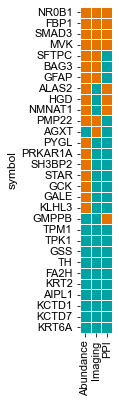

Hit rate: 66.667%


In [ ]:
# Sort by row sum (total number of assays passed) - largest to smallest
# First calculate row sums treating NaN as 0 for sorting purposes
row_sums = heatmap_data.fillna(0).sum(axis=1)
sort_order = row_sums.sort_values(ascending=False).index
heatmap_data = heatmap_data.loc[sort_order]

# Create mask AFTER sorting
mask = heatmap_data.isna()

# Convert boolean to int, but keep NaN as NaN initially
heatmap_data_filled = heatmap_data.astype(float)  # Keep as float to preserve NaN

# Create custom colormap: blue for False (0), red for True (1)
colors = ['#00A3A3', '#E67300']  # blue, red
custom_cmap = ListedColormap(colors)

# Set the bad color (for masked values) to light grey
custom_cmap.set_bad(color='lightgrey')

fig, ax = plt.subplots(1,1,figsize=(6,6))
sns.heatmap(heatmap_data_filled, 
            # mask=panel1_mask,
            cmap=custom_cmap, 
            square=True,
            cbar=False,
            linewidths=0.5,
            linecolor='white',
            ax=ax,
            yticklabels=True,
            vmin=0, vmax=1
)
plt.show()

hit_rate = heatmap_data_filled.loc[heatmap_data_filled.sum(axis=1) > 0,:].shape[0] / heatmap_data_filled.shape[0]
print(f"Hit rate: {hit_rate*100:.3f}%")

In [ ]:
heatmap_data.shape

(30, 3)

In [ ]:
plt.clf()
# Prepare data for heatmap - handle NaN values properly
heatmap_data = merged_genes_any_path.loc[:,["Passes_Threshold_dualipa", "Passes_Threshold_imaging", "Passes_Threshold"]].rename(
    {
        "Passes_Threshold_dualipa": "Abundance",
        "Passes_Threshold_imaging": "Imaging",
        "Passes_Threshold": "PPI"
    }, axis=1
).copy()

heatmap_data["Row_NA_sum"] = heatmap_data.isna().sum(axis=1)

<Figure size 432x288 with 0 Axes>

In [ ]:
# # Prepare data for heatmap - handle NaN values properly
# heatmap_data = merged_genes[["Passes_Threshold_imaging", "Passes_Threshold_dualipa", "Passes_Threshold"]].rename(
#     {
#         "Passes_Threshold_imaging": "Imaging",
#         "Passes_Threshold_dualipa": "DUAL-IPA",
#         "Passes_Threshold": "PPI"
#     }, axis=1
# ).copy()

# # Sort by row sum (total number of assays passed) - largest to smallest
# # First calculate row sums treating NaN as 0 for sorting purposes
# row_sums = heatmap_data.fillna(0).sum(axis=1)
# sort_order = row_sums.sort_values(ascending=False).index
# heatmap_data = heatmap_data.loc[sort_order]

# # Create mask AFTER sorting
# mask = heatmap_data.isna()

# # Convert boolean to int, but keep NaN as NaN initially
# heatmap_data_filled = heatmap_data.astype(float)  # Keep as float to preserve NaN

# # Create custom colormap: blue for False (0), red for True (1)
# colors = ['#1f77b4', '#d62728']  # blue, red
# custom_cmap = ListedColormap(colors)

# # Set the bad color (for masked values) to light grey
# custom_cmap.set_bad(color='lightgrey')

# # Split into 3 horizontal panels with ~50 genes each
# n_genes = len(heatmap_data_filled)
# genes_per_panel = 52
# n_panels = 3
# genes_panel1 = min(genes_per_panel, n_genes)
# genes_panel2 = min(genes_per_panel, max(0, n_genes - genes_panel1))
# genes_panel3 = max(0, n_genes - genes_panel1 - genes_panel2)

# # Use gridspec for better control over spacing
# from matplotlib.gridspec import GridSpec
# fig = plt.figure(figsize=(18, 15))
# gs = GridSpec(1, 3, width_ratios=[1, 1, .67], wspace=-.94)  # Extra width for panel 3 colorbar
# axes = [fig.add_subplot(gs[0, i]) for i in range(3)]

# # Panel 1: First ~50 genes
# if genes_panel1 > 0:
#     panel1_data = heatmap_data_filled.iloc[:genes_panel1]
#     panel1_mask = mask.iloc[:genes_panel1]
#     sns.heatmap(panel1_data, 
#                 mask=panel1_mask,
#                 cmap=custom_cmap, 
#                 square=True,
#                 cbar=False,
#                 linewidths=0.5,
#                 linecolor='white',
#                 ax=axes[0],
#                 yticklabels=True,
#                 vmin=0, vmax=1
#                 )
#     axes[0].set_ylabel('Gene Symbol', fontsize=10)
#     axes[0].set_xlabel('Assay Type')
#     axes[0].set_title(f'Functional Assay\nDistinguishable Genes')
#     axes[0].tick_params(axis='y', labelsize=9)

# # Panel 2: Next ~50 genes
# if genes_panel2 > 0:
#     panel2_data = heatmap_data_filled.iloc[genes_panel1:genes_panel1+genes_panel2]
#     panel2_mask = mask.iloc[genes_panel1:genes_panel1+genes_panel2]
    
#     sns.heatmap(panel2_data, 
#                 mask=panel2_mask,
#                 cmap=custom_cmap, 
#                 square=True,
#                 cbar=False,
#                 linewidths=0.5,
#                 linecolor='white',
#                 ax=axes[1],
#                 yticklabels=True,
#                 vmin=0, vmax=1
#                 )
#     axes[1].set_ylabel('')
#     axes[1].set_xlabel('Assay Type')
#     axes[1].set_title(f'Functional Assay\nNon-Distinguishable Genes')
#     axes[1].tick_params(axis='y', labelsize=9)
# else:
#     axes[1].set_visible(False)

# # Panel 3: Remaining genes
# if genes_panel3 > 0:
#     panel3_data = heatmap_data_filled.iloc[genes_panel1+genes_panel2:]
#     panel3_mask = mask.iloc[genes_panel1+genes_panel2:]
    
#     sns.heatmap(panel3_data, 
#                 mask=panel3_mask,
#                 cmap=custom_cmap, 
#                 square=True,
#                 cbar_kws={'ticks': [0, 1], 'label': 'Distinguish\nPathogenic vs Benign', 'shrink': 0.3, 'format': FixedFormatter(['False', 'True'])},
#                 linewidths=0.5,
#                 linecolor='white',
#                 ax=axes[2],
#                 yticklabels=True,
#                 vmin=0, vmax=1
#                 )
#     axes[2].set_ylabel('')
#     axes[2].set_xlabel('Assay Type')
#     axes[2].set_title(f'Functional Assay\nNon-Distinguishable Genes')
#     axes[2].tick_params(axis='y', labelsize=9)
# else:
#     axes[2].set_visible(False)

# # plt.suptitle('Gene Performance Across Assays (Sorted by Total Passes)\n(Red=Pass, Blue=Fail, Grey=No Data)', y=0.95)
# plt.show()
# # merged_genes

<Figure size 432x288 with 0 Axes>

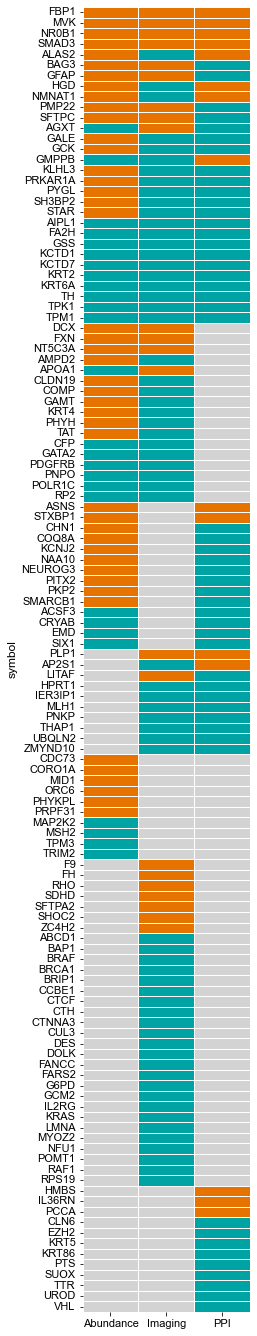

In [ ]:
plt.clf()
# Prepare data for heatmap - handle NaN values properly
heatmap_data = merged_genes_any_path.loc[:,["Passes_Threshold_dualipa", "Passes_Threshold_imaging", "Passes_Threshold"]].rename(
    {
        "Passes_Threshold_dualipa": "Abundance",
        "Passes_Threshold_imaging": "Imaging",
        "Passes_Threshold": "PPI"
    }, axis=1
).copy()

heatmap_data["Row_NA_sum"] = heatmap_data.isna().sum(axis=1)
heatmap_data["Row_Sum"] = heatmap_data[["Abundance","Imaging","PPI"]].sum(axis=1)
heatmap_data["Row_Abun"] = heatmap_data[["Abundance"]].isna()
heatmap_data["Row_Img"] = heatmap_data[["Imaging"]].isna()
heatmap_data["Row_PPI"] = heatmap_data[["PPI"]].isna()

heatmap_data["Gene"] = heatmap_data.index

heatmap_data = heatmap_data.sort_values(
    by=["Row_NA_sum", "Row_Abun", "Row_Img", "Row_PPI", "Row_Sum", "Gene"], ##, 
    ascending=[True, True, True, True, False, True]
)

# Create mask AFTER sorting
mask = heatmap_data[["Abundance", "Imaging", "PPI"]].isna()

# Convert boolean to int, but keep NaN as NaN initially
heatmap_data_filled = heatmap_data[["Abundance", "Imaging", "PPI"]].astype(float)  # Keep as float to preserve NaN

# Create custom colormap: blue for False (0), red for True (1)
colors = ['#00A3A3', '#E67300']  # blue, red
custom_cmap = ListedColormap(colors)

# Set the bad color (for masked values) to light grey
custom_cmap.set_bad(color='lightgrey')

fig, ax = plt.subplots(1,1,figsize=(3,24))
sns.heatmap(heatmap_data_filled, 
            # mask=panel1_mask,
            cmap=custom_cmap, 
            # square=True,
            cbar=False,
            linewidths=0.5,
            linecolor='white',
            ax=ax,
            yticklabels=True,
            vmin=0, vmax=1
)
# plt.tight_layout()
plt.savefig("../4_manuscript_figures/assay_hit_per_gene.svg", dpi=400, transparent=True, bbox_inches='tight')
plt.show()

In [ ]:
# plt.clf()
# # Prepare data for heatmap - handle NaN values properly
# heatmap_data = merged_genes_any_path.loc[:,["Passes_Threshold_dualipa", "Passes_Threshold_imaging", "Passes_Threshold"]].rename(
#     {
#         "Passes_Threshold_dualipa": "Abundance",
#         "Passes_Threshold_imaging": "Imaging",
#         "Passes_Threshold": "PPI"
#     }, axis=1
# ).copy()

# # Sort by row sum (total number of assays passed) - largest to smallest
# # First calculate row sums treating NaN as 0 for sorting purposes
# row_sums = heatmap_data.fillna(0).sum(axis=1)
# sort_order = row_sums.sort_values(ascending=False).index
# heatmap_data = heatmap_data.loc[sort_order]

# # Create mask AFTER sorting
# mask = heatmap_data.isna()
# # Convert boolean to int, but keep NaN as NaN initially
# heatmap_data_filled = heatmap_data.astype(float)  # Keep as float to preserve NaN

# genes_panel1 = merged_genes_any_path[merged_genes_any_path["non_null_count"]==3].index
# genes_panel2 = merged_genes_any_path[merged_genes_any_path["non_null_count"]==2].index
# genes_panel3 = merged_genes_any_path[merged_genes_any_path["non_null_count"]==1].index

# # Use gridspec for better control over spacing
# # Calculate proportional widths based on gene counts
# n1, n2, n3 = len(genes_panel1), len(genes_panel2), len(genes_panel3)
# total = n1 + n2 + n3

# fig = plt.figure(figsize=(10, 10))
# # gs = GridSpec(1, 3, 
# #               width_ratios=[n1/total, n2/total, n3/total],  # Proportional to gene count
# #               wspace=0.3)  # Positive value for consistent spacing
# # [left, bottom, width, height] in figure coordinates
# # axes = [fig.add_subplot(gs[0, i]) for i in range(3)]

# ax1 = fig.add_axes([0.06, 0.1, 0.1, 0.8])   # Panel 1
# ax2 = fig.add_axes([0.185, 0.1, 0.22, 0.8])   # Panel 2 (gap = 0.02)
# ax3 = fig.add_axes([0.27, 0.1, 0.40, 0.8])   # Panel 3 (gap = 0.07)
# axes = [ax1, ax2, ax3]

# # Panel 1: First ~50 genes
# if len(genes_panel1) > 0:
#     panel1_data = heatmap_data_filled.loc[genes_panel1,]
#     panel1_mask = mask.loc[genes_panel1,]
#     sns.heatmap(panel1_data, 
#                 mask=panel1_mask,
#                 cmap=custom_cmap, 
#                 # square=True,
#                 cbar=False,
#                 linewidths=0.5,
#                 linecolor='white',
#                 ax=axes[0],
#                 yticklabels=True,
#                 vmin=0, vmax=1
#                 )
#     axes[0].set_ylabel('Gene Symbol', fontsize=10)
#     axes[0].set_xlabel('Assay Type')
#     axes[0].set_title(f'3 Assays Profiled')
#     axes[0].tick_params(axis='y', labelsize=9)
#     axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=90) #, ha="right"
#     # axes[0].set_aspect(0.5)

# # Panel 2: Next ~50 genes
# if len(genes_panel2) > 0:
#     panel2_data = heatmap_data_filled.loc[genes_panel2,]
#     panel2_mask = mask.loc[genes_panel2,]
    
#     sns.heatmap(panel2_data, 
#                 mask=panel2_mask,
#                 cmap=custom_cmap, 
#                 # square=True,
#                 cbar=False,
#                 linewidths=0.5,
#                 linecolor='white',
#                 ax=axes[1],
#                 yticklabels=True,
#                 vmin=0, vmax=1
#                 )
#     axes[1].set_ylabel('')
#     axes[1].set_xlabel('Assay Type')
#     axes[1].set_title(f'2 Assays Profiled')
#     axes[1].tick_params(axis='y', labelsize=9)
#     axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=90) #, ha="right"
#     axes[1].set_aspect(0.5)
# else:
#     axes[1].set_visible(False)

# # Panel 3: Remaining genes
# if len(genes_panel3) > 0:
#     panel3_data = heatmap_data_filled.loc[genes_panel3,]
#     panel3_mask = mask.loc[genes_panel3,]
    
#     sns.heatmap(panel3_data, 
#                 mask=panel3_mask,
#                 cmap=custom_cmap, 
#                 # square=True,
#                 cbar=False,
#                 # cbar_kws={'ticks': [0, 1], 'label': 'Phenotype Hit', 'shrink': 0.1, 'format': 
#                 # FixedFormatter(['False', 'True'])},
#                 linewidths=0.5,
#                 linecolor='white',
#                 ax=axes[2],
#                 yticklabels=True,
#                 vmin=0, vmax=1
#                 )
#     axes[2].set_ylabel('')
#     axes[2].set_xlabel('Assay Type')
#     axes[2].set_title(f'1 Assay Profiled')
#     axes[2].tick_params(axis='y', labelsize=9)
#     axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=90) #, ha="center"
#     axes[2].set_aspect(0.5)
# else:
#     axes[2].set_visible(False)

# # Manual colorbar as legend
# legend_elements = [
#     Patch(facecolor='#E67300', edgecolor='white', label='True'),
#     Patch(facecolor='#00A3A3', edgecolor='white', label='False'),
#     Patch(facecolor='lightgrey', edgecolor='white', label='No Data')
# ]

# # Position legend on right side
# fig.legend(
#     handles=legend_elements,
#     loc='center right',
#     title='Assay Hit',
#     frameon=True,
#     bbox_to_anchor=(0.66, 0.5)
# )
# # plt.suptitle('Gene Performance Across Assays (Sorted by Total Passes)\n(Red=Pass, Blue=Fail, Grey=No Data)', y=0.95)
# plt.tight_layout()
# plt.savefig("../4_manuscript_figures/assay_hit_per_gene.svg", dpi=400, transparent=True, bbox_inches='tight')
# plt.show()
# # merged_genes

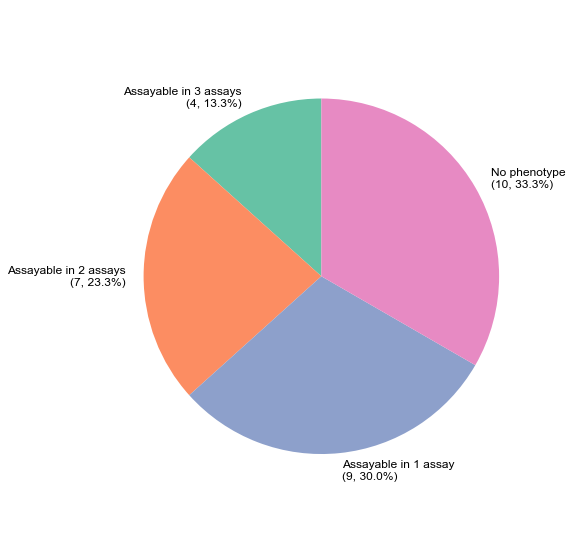

Assayable in 3 assays: 4 genes (13.3%)
Assayable in 2 assays: 7 genes (23.3%)
Assayable in 1 assay: 9 genes (30.0%)
No phenotype: 10 genes (33.3%)

Total genes: 30


In [ ]:
# Create pie chart for ClinVar annotation categories
merged_genes_any_path_pl = pl.DataFrame(merged_genes_any_path).with_columns(
    pl.when(pl.col("true_count")==0)
    .then(pl.lit("No phenotype"))
    .when(pl.col("true_count")==1)
    .then(pl.lit("Assayable in 1 assay"))
    .when(pl.col("true_count")==2)
    .then(pl.lit("Assayable in 2 assays"))
    .otherwise(pl.lit("Assayable in 3 assays"))
    .alias("Assayable")
).filter(
    pl.col("non_null_count")==3
)
# Get the category counts from the merged data
summary_clin_var_counts = merged_genes_any_path_pl.group_by("Assayable").len() #.sort("clinvar_clnsig_clean")#.sort("len", descending=True)
summary_clin_var_counts = merged_genes_any_path_pl.group_by("Assayable").len().to_pandas()
category_order = ["Assayable in 3 assays", "Assayable in 2 assays", "Assayable in 1 assay", "No phenotype"]
summary_clin_var_counts['Assayable'] = pd.Categorical(summary_clin_var_counts['Assayable'], categories=category_order, ordered=True)

# Convert to pandas for easier plotting
pie_data = summary_clin_var_counts.sort_values('Assayable')
pie_data = pie_data.dropna()  # Remove any null values

# Calculate percentages
total_count = pie_data["len"].sum()
pie_data["percentage"] = (pie_data["len"] / total_count * 100).round(1)

# Create labels with counts and percentages
labels = [f"{cat}\n({count}, {pct}%)" 
          for cat, count, pct in zip(pie_data["Assayable"], 
                                   pie_data["len"], 
                                   pie_data["percentage"])]

# Use a color palette that matches the boxenplot
# colors = list(palette_dict["clinvar_clnsig_clean"].values())
# colors[1], colors[3] = colors[3], colors[1]  # Swap colors to match the order in pie chart
# Create pie chart
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
wedges, texts, autotexts = ax.pie(pie_data["len"], 
                                  labels=labels, 
                                  colors=sns.color_palette("Set2"),
                                  autopct="",  # We're including percentages in labels
                                  startangle=90,
                                  textprops={'fontsize': 12})

# ax.set_title("Distribution of Molecular Phenotype Detection Rate", y=.90, fontsize=14, fontweight='bold', pad=0)
# Equal aspect ratio ensures that pie is drawn as a circle
ax.axis('equal')

# # Add a legend
# ax.legend(wedges, [f"{cat} (n={count})" for cat, count in zip(pie_data["clinvar_clnsig_clean"], pie_data["len"])],
#           title="Categories",
#           loc="center left",
#           bbox_to_anchor=(1, 0, 0.5, 1))

plt.tight_layout()
plt.savefig("../4_manuscript_figures/gene_assayability.svg", dpi=400, transparent=True, bbox_inches='tight')
plt.show()

# Print summary statistics
print("=" * 40)
for _, row in pie_data.iterrows():
    print(f"{row['Assayable']}: {row['len']} genes ({row['percentage']}%)")
print(f"\nTotal genes: {total_count}")

### 3.2 VUS analyses

symbol,gene_variant,nt_change,aa_change,spdi,tested_DUAL-IPA,tested_Imaging,tested_PPI,hit_DUAL-IPA,hit_Imaging,hit_PPI,dualipa_score,imaging_score,ppi_score
str,str,str,str,str,bool,bool,bool,bool,bool,bool,f64,f64,f64
"""ACSF3""","""ACSF3_Arg10Trp""","""28C>T""","""Arg10Trp""","""NC_000016.10:89100708:C:T""",false,false,true,false,false,true,null,null,0.673632
"""ACSF3""","""ACSF3_Asp457Asn""","""1369G>A""","""Asp457Asn""","""NC_000016.10:89145268:G:A""",true,false,true,false,false,false,-1.223509,null,0.506415
"""ACSF3""","""ACSF3_Gly119Asp""","""356G>A""","""Gly119Asp""","""NC_000016.10:89101036:G:A""",true,false,true,false,false,false,-0.72648,null,0.389524
"""ACSF3""","""ACSF3_Gly225Arg""","""673G>A""","""Gly225Arg""","""NC_000016.10:89102609:G:A""",true,false,false,false,false,null,-1.094508,null,null
"""ACSF3""","""ACSF3_Met266Val""","""796A>G""","""Met266Val""","""NC_000016.10:89102732:A:G""",true,false,false,false,false,null,-0.323287,null,null
…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""TUFM""","""TUFM_Arg339Gln""","""1016G>A""","""Arg339Gln""","""NC_000016.10:28844007:C:T""",true,false,false,false,false,null,-1.145394,null,null
"""UBQLN2""","""UBQLN2_Pro509Ser""","""1525C>T""","""Pro509Ser""","""NC_000023.11:56565397:C:T""",false,true,true,false,false,false,null,0.503824,0.171597
"""UROD""","""UROD_Glu167Lys""","""499G>A""","""Glu167Lys""","""NC_000001.11:45013932:G:A""",false,false,true,false,false,false,null,null,0.119462


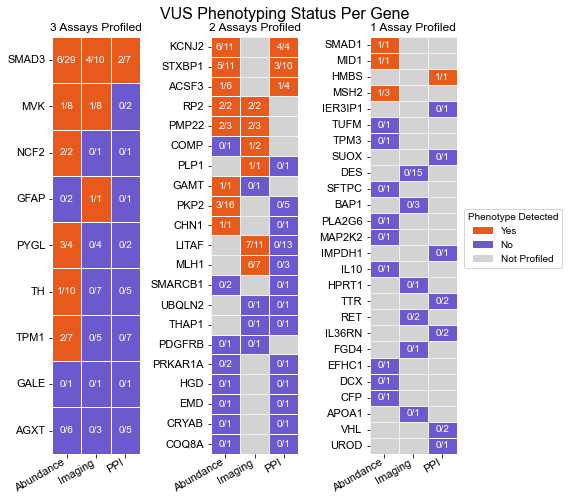

In [ ]:
vus = al_dual_img_ppi_assayed_dedup.filter(
    (pl.col("clinvar_clnsig_clean_pp_strict") == "VUS")
)

vus_detailed = vus.with_columns(
    pl.col("dualipa_score").is_not_null().alias("tested_DUAL-IPA"),
    pl.col("imaging_score").is_not_null().alias("tested_Imaging"),
    pl.col("ppi_score").is_not_null().alias("tested_PPI"),
    pl.when(pl.col("dualipa_abun_change")=="Y")
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("hit_DUAL-IPA"),
    pl.when(pl.col("img_pheno_hit"))
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("hit_Imaging"),
    pl.col("ppi_hit").alias("hit_PPI")
).select([
    "symbol",
    "gene_variant",
    "nt_change",
    "aa_change",
    "spdi",
    "tested_DUAL-IPA",
    "tested_Imaging", 
    "tested_PPI",
    "hit_DUAL-IPA",
    "hit_Imaging",
    "hit_PPI",
    "dualipa_score",
    "imaging_score",
    "ppi_score"
]).sort("symbol", "gene_variant")
display(vus_detailed)

# Also create a summary per gene
vus_gene_summary = vus_detailed.group_by("symbol").agg([
    pl.len().alias("num_VUS"),
    pl.col("tested_DUAL-IPA").sum().alias("tested_DUAL-IPA"),
    pl.col("tested_Imaging").sum().alias("tested_Imaging"),
    pl.col("tested_PPI").sum().alias("tested_PPI"),
    pl.col("hit_DUAL-IPA").sum().alias("hit_DUAL-IPA"),
    pl.col("hit_Imaging").sum().alias("hit_Imaging"),
    pl.col("hit_PPI").sum().alias("hit_PPI")
]).with_columns([
    (pl.col("hit_DUAL-IPA") / pl.col("tested_DUAL-IPA") * 100).round(1).alias("hit_rate_DUAL-IPA_perc"),
    (pl.col("hit_Imaging") / pl.col("tested_Imaging") * 100).round(1).alias("hit_rate_Imaging_perc"),
    (pl.col("hit_PPI") / pl.col("tested_PPI") * 100).round(1).alias("hit_rate_PPI_perc")
]).sort("num_VUS", descending=True)

# Display both tables
# print("VUS Detailed Table (first 10 rows):")
# display(vus_detailed.head(10))

# print("\nVUS Gene Summary Table:")
# display(vus_gene_summary)

# vus.group_by("symbol").agg(
#     pl.len().alias("num_VUS")
# ).sort("num_VUS", descending=True).write_csv("../3_outputs/vus_per_gene.csv", separator=",")

# vus_gene_summary.write_csv("../3_outputs/0_vus_per_gene_with_assay_summary.csv")

# Save detailed VUS table
# vus_detailed.write_csv("../3_outputs/0_vus_detailed_with_assays.csv")



vus_hit_assay = vus_gene_summary.select(
    pl.col('symbol', "hit_rate_DUAL-IPA_perc","hit_rate_Imaging_perc","hit_rate_PPI_perc")
).rename(
    {
        "hit_rate_DUAL-IPA_perc": "Abundance",
        "hit_rate_Imaging_perc": "Imaging",
        "hit_rate_PPI_perc": "PPI"
    }
).to_pandas().set_index("symbol")

vus_hit_assay_sum = vus_hit_assay.apply(lambda x: np.where(x.isna(), np.nan, x > 0))
vus_hit_assay = vus_hit_assay.loc[vus_hit_assay_sum.sum(axis=1).sort_values(ascending=False).index,:]

# Create binary mask: True if > 0, False if == 0, NaN stays NaN
binary_df = vus_hit_assay.apply(lambda x: np.where(x.isna(), np.nan, x > 0))
# Count NaNs per row
nan_counts = binary_df.isna().sum(axis=1)
# Split into three groups
df_0nan = binary_df[nan_counts == 0]  # All assays profiled
df_1nan = binary_df[nan_counts == 1]  # Two assays profiled
df_2nan = binary_df[nan_counts == 2]  # One assay profiled

total_df = vus_gene_summary.select(
    pl.col('symbol', "tested_DUAL-IPA","tested_Imaging","tested_PPI")
).rename(
    {
        "tested_DUAL-IPA": "Abundance",
        "tested_Imaging": "Imaging",
        "tested_PPI": "PPI"
    }
).to_pandas().set_index("symbol")

hits_df = vus_gene_summary.select(
    pl.col('symbol', "hit_DUAL-IPA","hit_Imaging","hit_PPI")
).rename(
    {
        "hit_DUAL-IPA": "Abundance",
        "hit_Imaging": "Imaging",
        "hit_PPI": "PPI"
    }
).to_pandas().set_index("symbol")

# Build string annotation matrix
annot_df = hits_df.astype(int).astype(str) + "/" + total_df.astype(int).astype(str)
annot_df = annot_df.loc[binary_df.index, binary_df.columns]
annot_df = annot_df.where(~vus_hit_assay.isna(), "")  # blank for NaN cells

# Split annotation matrix same way as data
nan_counts = binary_df.isna().sum(axis=1)
annot_0nan = annot_df[nan_counts == 0]
annot_1nan = annot_df[nan_counts == 1]
annot_2nan = annot_df[nan_counts == 2]
annots = [annot_0nan, annot_1nan, annot_2nan]

# Warm/cool palette: cool mint for False, warm orange for True
cmap = ListedColormap(['slateblue', '#E85A1B'])

fig, axes = plt.subplots(1, 3, figsize=(8, max(len(df_0nan), len(df_1nan), len(df_2nan)) * 0.2 + 2))

dfs = [df_0nan, df_1nan, df_2nan]
titles = ['3 Assays Profiled', '2 Assays Profiled', '1 Assay Profiled']

for ax, sub_df, annot_sub, title_base in zip(axes, dfs, annots, titles):
    if len(sub_df) == 0:
        ax.set_visible(False)
        continue
    
    hit_rate = (sub_df.max(axis=1) > 0).mean() * 100
    
    sns.heatmap(
        sub_df.astype(float),
        cmap=cmap,
        vmin=0,
        vmax=1,
        linewidths=0.5,
        linecolor='white',
        cbar=False,
        ax=ax,
        mask=sub_df.isna(),
        annot=annot_sub,
        fmt="s",  # string format
        annot_kws={"fontsize": 10, "font": "arial"}
    )
    
    # Fill NaN cells with grey
    for i in range(sub_df.shape[0]):
        for j in range(sub_df.shape[1]):
            if pd.isna(sub_df.iloc[i, j]):
                ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=True, color='#D3D3D3', ec='white', lw=0.5))
    
    ax.set_title(f'{title_base}') ## \n{hit_rate:.1f}% genes hit (n={len(sub_df)})
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
    ax.tick_params(axis='x', pad=0)

axes[0].set_yticklabels(axes[0].get_yticklabels(), rotation=0)
# Shared legend on rightmost axis
legend_elements = [
    Patch(facecolor='#E85A1B', label='Yes'),
    Patch(facecolor='slateblue', label='No'),
    Patch(facecolor='#D3D3D3', label='Not Profiled'),
]
axes[-1].legend(handles=legend_elements, loc='upper left', title="Phenotype Detected", bbox_to_anchor=(1.02, .6))

plt.suptitle("VUS Phenotyping Status Per Gene", fontsize=16, y=.96)
plt.subplots_adjust(wspace=2)
plt.tight_layout()
fig.savefig(
    "../4_manuscript_figures/VUS_phenotype.svg",
    format='svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)
plt.show()

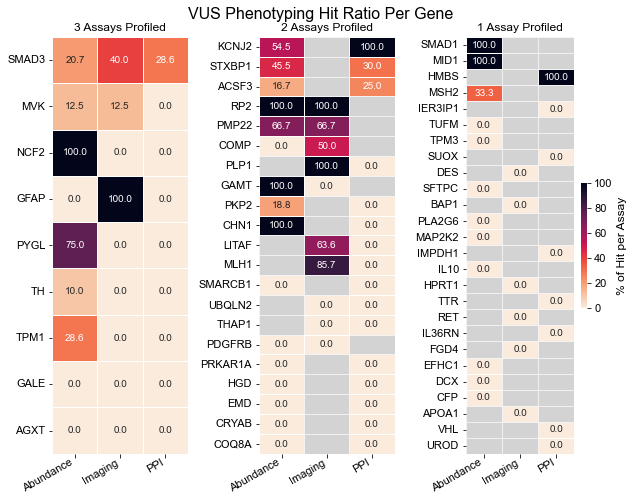

In [ ]:
# Count NaNs per row
nan_counts = vus_hit_assay.isna().sum(axis=1)

# Split into three groups
df_0nan = vus_hit_assay[nan_counts == 0]  # All assays profiled
df_1nan = vus_hit_assay[nan_counts == 1]  # Two assays profiled
df_2nan = vus_hit_assay[nan_counts == 2]  # One assay profiled

fig, axes = plt.subplots(1, 3, figsize=(9, max(len(df_0nan), len(df_1nan), len(df_2nan)) * 0.2 + 2))
dfs = [df_0nan, df_1nan, df_2nan]
titles = ['3 Assays Profiled', '2 Assays Profiled', '1 Assay Profiled']
for ax, sub_df, title_base in zip(axes, dfs, titles):
    if len(sub_df) == 0:
        ax.set_visible(False)
        continue
    
    # Calculate hit rate: gene is hit if max value in row > 0
    hit_rate = (sub_df.max(axis=1) > 0).mean() * 100
    
    sns.heatmap(
        sub_df.astype(float),
        cmap="rocket_r",
        vmin=0,
        vmax=100,
        linewidths=0.5,
        linecolor='white',
        cbar=(ax == axes[-1]),  # Only show colorbar on last axis
        cbar_kws={'label': '% of Hit per Assay', 'shrink': 0.3, 'pad': 0.05} if ax == axes[-1] else {},
        ax=ax,
        mask=sub_df.isna(),
        annot=True,
        fmt=".1f"
    )
    # Fill NaN cells with grey
    for i in range(sub_df.shape[0]):
        for j in range(sub_df.shape[1]):
            if pd.isna(sub_df.iloc[i, j]):
                ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=True, color='#D3D3D3', ec='white', lw=0.5))
    
    ax.set_title(f'{title_base}') ## \n{hit_rate:.1f}% genes hit (n={len(sub_df)})
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
    ax.tick_params(axis='x', pad=0)

axes[0].set_yticklabels(axes[0].get_yticklabels(), rotation=0)
# Shared legend on rightmost axis
# legend_elements = [
#     Patch(facecolor='#E85A1B', label='Yes'),
#     Patch(facecolor='#A8E6CF', label='No'),
#     Patch(facecolor='#D3D3D3', label='Not Profiled'),
# ]
# axes[-1].legend(loc='upper left', title="Molecular Phenotype", bbox_to_anchor=(1.02, .6))
plt.suptitle("VUS Phenotyping Hit Ratio Per Gene", fontsize=16, y=.96)
plt.subplots_adjust(wspace=1.4)
plt.tight_layout()
fig.savefig(
    "../4_manuscript_figures/VUS_phenotype_ratio.svg",
    format='svg',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)
plt.show()

## 4. Variant-level Analyses

### 4.1 Gene alleles profiled by ALL 3 assays

In [ ]:
meta_cols = ["symbol", "gene_variant", "ensembl_gene_id", "spdi", "orf_id", "mut_id", 
             "nt_change", "aa_change", "clinvar_clnsig_clean", "clinvar_clnsig_clean_pp_strict", "gnomAD4.1_joint_AF", "StarStatus",
             "inheritance_pattern", "AlphaMissense_score", "AlphaMissense_rankscore", "AlphaMissense_pred", 
             "ESM1b_score", "ESM1b_rankscore", "ESM1b_pred",
             "plddt_f32", "rsa_f32", "RSA_Category", "pLDDT_Category"]
dualipa_cols = ["dualipa_score", "dualipa_abun_change", "dualipa_abun_chg_dir"]
img_cols = ["imaging_score", "img_pheno_hit"] ## "AUROC_Mean_DNA", "Altered_95th_perc_both_batches_DNA"
ppi_cols = ["ppi_score", "ppi_hit"]

al_dual_img_ppi_key_cols = al_dual_img_ppi_assayed_dedup.select(
    pl.col(meta_cols + dualipa_cols + img_cols + ppi_cols)
)

### 3.2 Gene Alleles Profiled by AT LEAST ONE assay

In [ ]:
alleles_prof_one_assay = al_dual_img_ppi_key_cols.filter(
    ~pl.all_horizontal([pl.col(col).is_null() for col in dualipa_cols+img_cols+ppi_cols])
).unique(subset="gene_variant")
alleles_prof_one_assay.shape

(1427, 30)

In [ ]:
# palette_dict = {
#     "clinvar_clnsig_clean":{
#         '1_Pathogenic': "#CA7682",
#         '2_Benign': "#1D7AAB",
#         '3_Conflicting': "#E6B1B8", #"grey",
#         '4_VUS': "#A0A0A0",
#         '5_Others': "#A0A0A0"
#         # '6_No_ClinVar'
#     }
# }

# fig, axes = plt.subplots(1,3,figsize=(18,5))
# plot_cat_count_perc(
#     alleles_prof_one_assay,
#     "clinvar_clnsig_clean",
#     title="ClinVar",
#     ax=axes[0],
#     palette=palette_dict["clinvar_clnsig_clean"]
# )
# # axes[0].legend(loc="lower right")
# axes[0].set_title("Genetic Variant ClinVar Info")

# plot_cat_count_perc(
#     alleles_prof_one_assay.unique("symbol"),
#     "inheritance_pattern",
#     title="Inheritance",
#     ax=axes[1],
# )
# axes[1].set_title("Gene-level Inheritance Pattern")

# plot_cat_count_perc(
#     alleles_prof_one_assay,
#     "inheritance_pattern",
#     title="Inheritance",
#     ax=axes[2],
# )
# axes[2].set_title("Variant-level Inheritance Pattern")

# plt.suptitle(f"{alleles_prof_one_assay.unique('gene_variant').shape[0]} Variants from {alleles_prof_one_assay.unique('symbol').shape[0]} Genes Profiled by Any Functional Assay", y=.97, fontsize=14)
# plt.subplots_adjust(wspace=.6)
# plt.show()

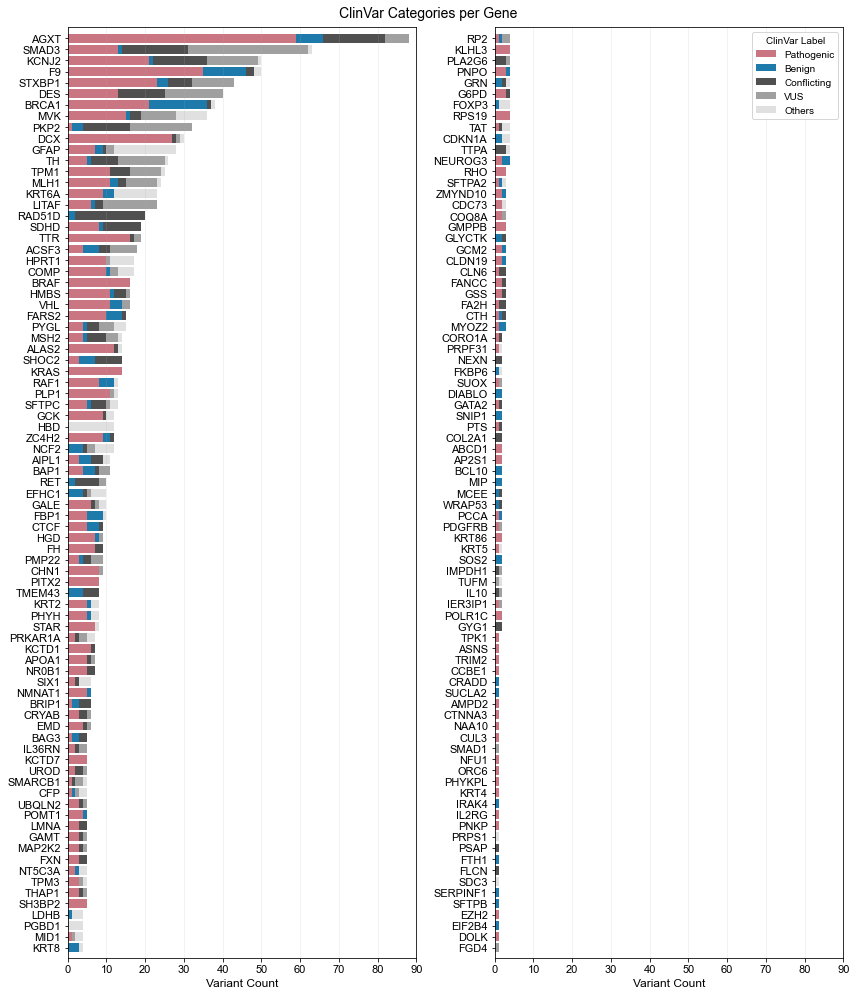

In [ ]:
# 2. Count per (gene, category)
df = al_dual_img_ppi_assayed_dedup.to_pandas() ## drop_nulls("clinvar_clnsig_clean").

top_num = int(np.ceil(al_dual_img_ppi_assayed_dedup.unique("symbol").shape[0] / 2))
counts = (
    df.groupby(["symbol", "clinvar_clnsig_clean"])
    .size()
    .reset_index(name="count")
)
# 3. Pivot
pivot = counts.pivot(index="symbol", columns="clinvar_clnsig_clean", values="count").fillna(0)

# Add total count column and sort by it (descending)
pivot["total_count"] = pivot.sum(axis=1)
pivot_top = pivot.sort_values("total_count", ascending=False).head(top_num)
pivot_top = pivot_top.drop(columns=["total_count"])
# category_order = sorted(pivot_top["clinvar_clnsig_clean"].unique())

# # 4. Ensure category order
# for cat in category_order:
#     if cat not in pivot_top.columns:
#         pivot_top[cat] = 0
# pivot_top = pivot_top[category_order]

# 5. Plotting
fig, axes = plt.subplots(1,2, figsize=(12, 14))
# Get Set2 colors
bottom = None
for cat, color in palette_dict["clinvar_clnsig_clean"].items():
    axes[0].barh(pivot_top.index, pivot_top[cat], 
            left=bottom, label=cat, color=color)
    bottom = pivot_top[cat] if bottom is None else bottom + pivot_top[cat]
    
# Axis formatting
axes[0].set_xlabel("Variant Count")
axes[0].set_xlim(None, 90)
axes[0].set_ylim(-1, pivot_top.shape[0] - .1)  # Tighten y-axis to remove top/bottom gaps
# axes[0].set_title(f"ClinVar Categories per Gene (Top {top_num} with Most Variants)", fontsize=14)
axes[0].invert_yaxis()
axes[0].grid(alpha=.2, axis="x")

# ax.legend(title="ClinVar Label", fontsize=9, title_fontsize=10, loc="lower right")
# plt.tight_layout()
# plt.show()

pivot_bot = pivot.sort_values("total_count", ascending=False).iloc[top_num:,].copy()
pivot_bot = pivot_bot.drop(columns=["total_count"])

# 4. Ensure category order
# for cat in category_order:
#     if cat not in pivot_bot.columns:
#         pivot_bot[cat] = 0
# pivot_bot = pivot_bot[category_order]

bottom = None
for cat, color in palette_dict["clinvar_clnsig_clean"].items():
    axes[1].barh(pivot_bot.index, pivot_bot[cat], left=bottom, label=cat, color=color)
    bottom = pivot_bot[cat] if bottom is None else bottom + pivot_bot[cat]
    
# Axis formatting
axes[1].set_xlabel("Variant Count")
axes[1].set_xlim(None, 90)
axes[1].set_ylim(-1, pivot_bot.shape[0] - .1)  # Tighten y-axis to remove top/bottom gaps
# axes[1].set_title(f"ClinVar Categories per Gene ({top_num} After)", fontsize=14)
axes[1].invert_yaxis()
axes[1].legend(title="ClinVar Label", fontsize=10, title_fontsize=10, loc="upper right")
axes[1].grid(alpha=.2, axis="x")
plt.suptitle(f"ClinVar Categories per Gene", fontsize=14, y=.985)
plt.tight_layout()
plt.show()

In [ ]:
# # Create pie chart for ClinVar annotation categories
# fig, ax = plt.subplots(1, 1, figsize=(8, 8))

# # Get the category counts from the merged data
# summary_clin_var_counts = alleles_prof_one_assay.group_by("clinvar_clnsig_clean").len() #.sort("clinvar_clnsig_clean")#.sort("len", descending=True)
# summary_clin_var_counts = alleles_prof_one_assay.group_by("clinvar_clnsig_clean").len().to_pandas()
# category_order = ["1_Pathogenic", "2_Benign", "3_Conflicting", "4_VUS", "5_Others"]
# summary_clin_var_counts['clinvar_clnsig_clean'] = pd.Categorical(summary_clin_var_counts['clinvar_clnsig_clean'], categories=category_order, ordered=True)

# # Convert to pandas for easier plotting
# pie_data = summary_clin_var_counts.sort_values('clinvar_clnsig_clean')
# pie_data = pie_data.dropna()  # Remove any null values

# # Calculate percentages
# total_count = pie_data["len"].sum()
# pie_data["percentage"] = (pie_data["len"] / total_count * 100).round(1)

# # Create labels with counts and percentages
# labels = [f"{cat.split('_')[1]}\n({count}, {pct}%)" 
#           for cat, count, pct in zip(pie_data["clinvar_clnsig_clean"], 
#                                    pie_data["len"], 
#                                    pie_data["percentage"])]

# # Use a color palette that matches the boxenplot
# colors = list(palette_dict["clinvar_clnsig_clean"].values())
# # colors[1], colors[3] = colors[3], colors[1]  # Swap colors to match the order in pie chart
# # Create pie chart
# wedges, texts, autotexts = ax.pie(pie_data["len"], 
#                                   labels=labels, 
#                                   colors=colors,
#                                   autopct="",  # We're including percentages in labels
#                                   startangle=90,
#                                   textprops={'fontsize': 12})

# ax.set_title("Distribution of ClinVar Annotation Categories", fontsize=14, fontweight='bold', pad=20)

# # Equal aspect ratio ensures that pie is drawn as a circle
# ax.axis('equal')

# # # Add a legend
# # ax.legend(wedges, [f"{cat} (n={count})" for cat, count in zip(pie_data["clinvar_clnsig_clean"], pie_data["len"])],
# #           title="Categories",
# #           loc="center left",
# #           bbox_to_anchor=(1, 0, 0.5, 1))

# plt.tight_layout()
# plt.show()

# # Print summary statistics
# print("ClinVar Annotation Distribution:")
# print("=" * 40)
# for _, row in pie_data.iterrows():
#     print(f"{row['clinvar_clnsig_clean']}: {row['len']} variants ({row['percentage']}%)")
# print(f"\nTotal variants: {total_count}")

In [ ]:
def plot_assay_hit_by_category_perc(df, hit_col, cat_cols, title="", ax=None):
    """
    plot_assay_hit_by_category
    ==========================
    
    Create a stacked horizontal bar chart showing hit rate percentage per category.
    Each bar represents 100% of the category, with the hit portion highlighted.
    
    Parameters
    ----------
    df : polars.DataFrame
        Input table containing at least the columns listed in `cat_cols` and a
        boolean column indicating hits.
    hit_col : str
        Name of the boolean column that flags hits (e.g. `"is_hit"`).
    cat_cols : str or list[str]
        Column(s) that define the categorical grouping(s).  If a single string is
        supplied it is handled automatically.
    title : str, optional
        Title placed above the plot.
    ax : matplotlib.axes.Axes, optional
        Pre-existing axes to draw on.  If None, a new figure and axes are created.
    
    Returns
    -------
    polars.DataFrame
        A tidy frame with one row per category, containing:
            - the grouping key(s)
            - total_counts   : total observations in that category
            - hit_counts     : observations that were hits
            - hit_perc       : hit rate in percent (hit_counts / total_counts * 100)
    """
    # --- compute hit counts and percentages ---
    df_tot_cnt_per_cat = (
        df.group_by(cat_cols)
        .len()
        .rename({"len": "total_counts"})
    )
    df_hit_cnt_per_cat = (
        df.unique("gene_variant")
        .filter(pl.col(hit_col))
        .group_by(cat_cols)
        .len()
        .rename({"len": "hit_counts"})
    )

    cat_col_name = cat_cols if isinstance(cat_cols, str) else cat_cols[-1]
    
    img_hits_perc_df = (
        df_tot_cnt_per_cat.join(
            df_hit_cnt_per_cat,
            on=cat_cols,
            how="left"
        )
        .fill_null(0)
        .with_columns(
            (pl.col("hit_counts") / pl.col("total_counts") * 100).alias("hit_perc")
        )
        .sort(cat_col_name, descending=True)
    )

    # --- plotting ---
    if ax is None:
        _, ax = plt.subplots(1, 1, figsize=(5, img_hits_perc_df.shape[0]))

    plot_df = img_hits_perc_df.to_pandas()
    y_positions = range(len(plot_df))

    # background bars (full 100% - gray)
    ax.barh(y_positions, [100] * len(plot_df), color='#00A3A3', label="Non-hit")
    # hit bars (foreground - red)
    ax.barh(y_positions, plot_df["hit_perc"], color='#E67300', label="Hit")

    # set labels
    ax.set_yticks(y_positions)
    ax.set_yticklabels([f"{cat}\n(n={n})" for cat, n in zip(plot_df[cat_col_name], plot_df["total_counts"])]) ##.split('_')[1]
    ax.set_xlabel("Percentage (%)")
    ax.set_xlim(0, 100)
    ax.set_title(title)
    ax.grid(axis='x', alpha=.2)
    ax.legend(loc='lower right')

    # percentage annotations - positioned at the end of hit bar
    for idx, row in plot_df.iterrows():
        ax.text(
            row["hit_perc"] + 1,
            idx,
            f"{row['hit_perc']:.1f}%",
            va="center",
            ha="left",
            fontweight="bold",
            fontsize=11,
            color="white"
        )
    return img_hits_perc_df


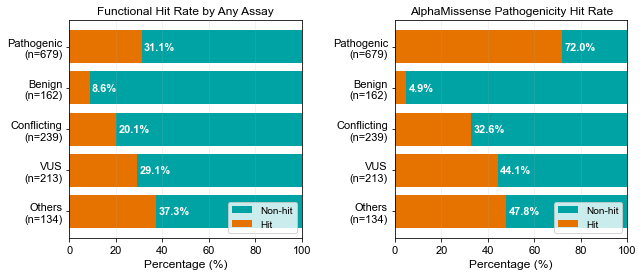

In [ ]:
alleles_prof_one_assay = al_dual_img_ppi_assayed_dedup.with_columns(
    pl.when((pl.col("dualipa_abun_change")=="Y") | (pl.col("imaging_hit")) | (pl.col("ppi_hit")))
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("any_assay_hit"),
    pl.col("gene_variant").alias("gene_allele")
)

fig, axes = plt.subplots(1,2,figsize=(10,4))
df = alleles_prof_one_assay.unique("gene_variant").to_pandas()
df["AlphaMissense_score"] = df["AlphaMissense_score"].replace(".",np.nan).astype(float)
df["AlphaMissense_pred_call"] = df["AlphaMissense_pred"].astype(str).apply(lambda x : True if "P" in x else False)

plot_assay_hit_by_category_perc(alleles_prof_one_assay.with_columns(
        pl.col("clinvar_clnsig_clean")
            .cast(pl.Enum(clinvar_order_dict["original"]))
    ).sort("clinvar_clnsig_clean"), 
    "any_assay_hit", "clinvar_clnsig_clean", 
    f"Functional Hit Rate by Any Assay",
    ax=axes[0]
)
plot_assay_hit_by_category_perc(
    pl.DataFrame(df).with_columns(
        pl.col("clinvar_clnsig_clean")
            .cast(pl.Enum(clinvar_order_dict["original"]))
    ).sort("clinvar_clnsig_clean"), 
    "AlphaMissense_pred_call", 
    "clinvar_clnsig_clean", 
    f"AlphaMissense Pathogenicity Hit Rate", 
    ax=axes[1]
)
plt.subplots_adjust(wspace=0.4)
# plt.savefig("../4_manuscript_figures/variant_hit_rate_per_clinvar.svg",  dpi=400, transparent=True, bbox_inches='tight')
plt.show()

In [ ]:
contingency_table = al_dual_img_ppi_assayed_dedup.with_columns(
    pl.when((pl.col("dualipa_abun_change")=="Y") | (pl.col("imaging_hit")) | (pl.col("ppi_hit")))
    .then(pl.lit(True))
    .otherwise(pl.lit(False))
    .alias("any_assay_hit")
).group_by(
    ["any_assay_hit", 'clinvar_clnsig_clean']
).agg(
    pl.len()
).pivot(
    index="any_assay_hit",
    on='clinvar_clnsig_clean',
    values="len"
).sort(
    "any_assay_hit", descending=True
)
print(
    contingency_table.select(
        (pl.col("Pathogenic").first() / pl.col("Pathogenic").sum()).alias("Pathogenic_hit_rate"),
        (pl.col("Benign").first() / pl.col("Benign").sum()).alias("Benign_hit_rate")
    )
)
table = contingency_table.select(["Pathogenic", "Benign"]).to_numpy()  # Flip so true is first row
odds_ratio, p_value = fisher_exact(table, alternative='two-sided')

print(p_value)

shape: (1, 2)
┌─────────────────────┬─────────────────┐
│ Pathogenic_hit_rate ┆ Benign_hit_rate │
│ ---                 ┆ ---             │
│ f64                 ┆ f64             │
╞═════════════════════╪═════════════════╡
│ 0.310751            ┆ 0.08642         │
└─────────────────────┴─────────────────┘
4.567974304437269e-10


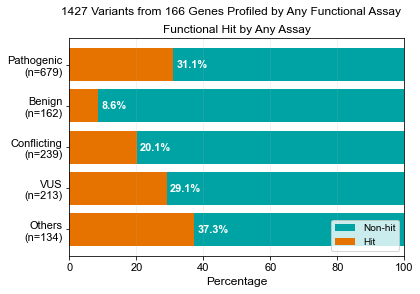

In [ ]:
fig, axes = plt.subplots(1,1,figsize=(6,4), sharey=False)
# plot_cat_count_perc(
#     alleles_prof_one_assay.with_columns(
#         pl.col("clinvar_clnsig_clean")
#             .cast(pl.Enum([c for c in clinvar_order_dict["original"] if "Likely" not in c]))
#     ).sort("clinvar_clnsig_clean"),
#     "clinvar_clnsig_clean",
#     title="ClinVar",
#     ax=axes[1],
#     palette=palette_dict["clinvar_clnsig_clean"]
# )
# axes[1].set_title("Genetic Variant ClinVar Distribution")
# axes[1].set_xlabel("Count")
# axes[1].set_ylabel("")
# axes[1].set_yticklabels("")
# axes[1].grid(alpha=.2)

plot_assay_hit_by_category_perc(
    alleles_prof_one_assay.with_columns(
        pl.col("clinvar_clnsig_clean")
            .cast(pl.Enum([c for c in clinvar_order_dict["original"] if "Likely" not in c]))
    ).sort("clinvar_clnsig_clean"), 
    "any_assay_hit", 
    "clinvar_clnsig_clean", 
    f"Functional Hit by Any Assay", 
    ax=axes
)
axes.set_xlabel("Percentage")

plt.suptitle(f"{alleles_prof_one_assay.unique('gene_variant').shape[0]} Variants from {alleles_prof_one_assay.unique('symbol').shape[0]} Genes Profiled by Any Functional Assay", y=.99, fontsize=12)
plt.subplots_adjust(wspace=.05)
plt.show()

### 3.3 Plot hits

In [ ]:
# from matplotlib.colors import ListedColormap
# from matplotlib.patches import Patch

# al_dual_img_ppi_intersect = al_dual_img_ppi_assayed_dedup.filter(
#     pl.col("dualipa_score").is_not_null(),
#     pl.col("imaging_score").is_not_null(),
#     pl.col("ppi_score").is_not_null()
# ).unique("gene_variant")

# df = al_dual_img_ppi_intersect.select(
#     pl.col(["symbol", "gene_variant", "dualipa_abun_change", "img_pheno_hit", "ppi_hit", "clinvar_clnsig_clean"])
# ).with_columns(
#     pl.when(pl.col("dualipa_abun_change")=="Y")
#     .then(pl.lit(1))
#     .otherwise(pl.lit(0))
#     .alias("Abundance"),
#     pl.col("img_pheno_hit").cast(pl.Int8).alias("Imaging"),
#     pl.col("ppi_hit").alias("PPI"),
# ).to_pandas()

# # Ensure hit columns are ints
# hit_cols = ['Abundance', 'Imaging', 'PPI']
# df[hit_cols] = df[hit_cols].astype(int)

# # Sort by gene symbol and ClinVar category
# df_sorted = df.sort_values(['symbol', 'clinvar_clnsig_clean'])

# # Create the hit matrix
# matrix = df_sorted.set_index('gene_variant')[hit_cols]

# # Row colors for ClinVar categories
# lut = palette_dict["clinvar_clnsig_clean"]
# row_colors_clinvar = df_sorted['clinvar_clnsig_clean'].map(lut).values

# # Split genes into three groups while keeping alleles together
# unique_genes = df_sorted['symbol'].unique()
# n_genes = len(unique_genes)
# split_point1 = n_genes // 3
# split_point2 = 2 * n_genes // 3

# genes_part1 = unique_genes[:split_point1]
# genes_part2 = unique_genes[split_point1:split_point2]
# genes_part3 = unique_genes[split_point2:]

# # Create three separate datasets
# df_part1 = df_sorted[df_sorted['symbol'].isin(genes_part1)]
# df_part2 = df_sorted[df_sorted['symbol'].isin(genes_part2)]
# df_part3 = df_sorted[df_sorted['symbol'].isin(genes_part3)]

# def create_clustermap_part(df_part, part_name, genes_subset):
#     # Create matrix for this part
#     matrix_part = df_part.set_index('gene_variant')[hit_cols]
    
#     # Row colors for ClinVar categories
#     row_colors_clinvar_part = df_part['clinvar_clnsig_clean'].map(lut).values
    
#     # Row colors for gene symbols (use consistent colors)
#     gene_palette = sns.color_palette("tab20", 20) + sns.color_palette("Set1", n_genes-20)
#     gene_lut = dict(zip(unique_genes, gene_palette))  # Keep all genes for consistent colors
#     row_colors_genes_part = [gene_lut[gene] for gene in df_part['symbol']]
    
#     # Combine row colors
#     row_colors_part = [row_colors_clinvar_part] #row_colors_genes_part
    
#     # Create clustermap
#     g = sns.clustermap(
#         matrix_part,
#         row_cluster=False,
#         col_cluster=False,
#         cmap=custom_cmap,
#         linewidths=0.5,
#         row_colors=row_colors_part,
#         figsize=(4.5,12),
#         colors_ratio=0.1,  # Increase from default 0.03 to make row colors wider
#         cbar_pos=(-0.2, 0.45, 0.05, 0.18),
#         cbar_kws={
#             "ticks": [0, 1],
#             "format": "%d",
#             "format": lambda x, pos: "False" if x == 0 else "True",
#         },
#         dendrogram_ratio=0.01,  # Remove dendrogram space
#         yticklabels=1
#     )
    
#     # Add legend for ClinVar categories
#     handles = [Patch(facecolor=color, label=label) for label, color in lut.items()]
#     g.ax_heatmap.legend(
#         handles=handles,
#         title='ClinVar',
#         bbox_to_anchor=(-1., 0.35),
#         loc='center left',
#         frameon=False,
#         fontsize=10
#     )
#     g.ax_heatmap.tick_params(axis='x', rotation=45)
#     # g.ax_heatmap.set_yticks(range(len(matrix_part)))
#     # g.ax_heatmap.set_yticklabels(matrix_part.index, fontsize=10, va='center')

#     # Change colorbar labels
#     # g.ax_cbar.set_yticklabels(['False', 'True'])
    
#     # plt.suptitle(f'{part_name} (Genes: {", ".join(genes_subset[:5])}{"..." if len(genes_subset) > 5 else ""})', 
#     #              y=1., fontsize=14)
#     plt.show()

# # Create both parts
# print(f"Part 1: {len(genes_part1)} genes, {len(df_part1)} variants")
# create_clustermap_part(df_part1, "Part 1", genes_part1)

# print(f"Part 2: {len(genes_part2)} genes, {len(df_part2)} variants")
# create_clustermap_part(df_part2, "Part 2", genes_part2)

# print(f"Part 2: {len(genes_part2)} genes, {len(df_part2)} variants")
# create_clustermap_part(df_part3, "Part 3", genes_part3)